<a href="https://colab.research.google.com/github/fadilaha/Ising-Model-on-Social-Opinion-Dynamic/blob/main/Experiment_D_HeatBath_AB_BC_Residual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#__Heat-Bath Dynamics with A-B Model Transition Rules and Blume-Capel Resistance Model__

This model has updated the rules of spin transition, adopting the A-B Model-inspired rules.  
__Transition Rules__  
*   +1 -> {+1, 0}; +1 can maintains its state or moves to 0  
*   0 -> {+1, 0, -1}; 0 can maintains its state or moves to +1 and -1  
*   -1 -> {0, -1}; -1 can maintains its state or moves to 0
*   Both +1 and -1 need to pass through 0 state first before transitioning to its opposites.  
In this logic, +1 and -1 can choose 0, and later:
1. Maintain its 0 state
2. Move to its opposite
3. Go back to its initial state  
The decision depends on the randomly drawn state by the system, based on the calculated probabilities for each possible states  

__The Probabilities__  

Just like the previous Heat-Bath Dynamics, for each selected spin, the probabilities of the three possible states are calculated based on their corresponding energies E($s'_i$) under the current effective field.  

$h_{eff}$ =  $h + JqM$  

$E(s'_i)$ = $-s'_i$($h_{eff}$) + $Ds'^2_i$  
where,  
$s'_i$ : possible new states of chosen spin  
$D$ : resistance parameter. It has negative value shows tendencies to maintain its non-neutral state.  

Boltzmann weight, $w($s'_i$) = e^{\frac{-E(s'_i)}{kB.T}}$  

Probability of a new state, $P($s'_i$) = {\frac{e^{\frac{-E(s'_i)}{kB.T}}}{(\sum_{s'_i} {w(s'_i)}}}$ ; $s'_i$ = {possible new state of the current chosen spin}

The system will draw a new state by randomly choose one element from possible_states. However, each element's chance of being chosen equal to the corresponding value in the previously calculated probabilities.  

__State-dependent neutrality (Blume-Capel D)__  

$E(s'_i)$ = $-s'_i$($h_{eff}$) + $Ds'^2_i$  

In this model, $D$ is always negative (resistance to leaving +1/-1) and its size depends on the collective opinion.

With $D_{0}$ = $D_{initial}$ (negative) and $dM$ = the distance of $|M|$ from the threshold of its band:

| Condition | dM | D |
|---|---|---|
| \|M\| < 0.5 | – | D0 |
| 0.5 ≤ \|M\| ≤ 0.6 | \|M\| − 0.5 | D0·(1 + k·dM) |
| \|M\| > 0.6 | \|M\| − 0.6 | −exp(\|D0\| + dM) |

\begin{cases} D_0= -0.5, & |M| < 0.5 \\ D_0\,(1 + dM), & 0.5 \le |M| \le 0.6 \\ -e^{\left(|D_0| + |dM|\right)}, & 0.6 < |M| \end{cases}

The further the majority is past its threshold, the stronger the resistance (D more negative). When the majority weakens (|M| falls), dM shrinks and the resistance weakens. Positive and negative majorities are treated the same because the rule uses |M|.

D is computed once at the start of each Monte Carlo step from M at the end of the previous step, and held fixed during that step.


In [57]:
#External Event Generator
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
# 1. PARAMETERS YOU CAN ADJUST
total_days = 250          # Total simulation period
appearance_interval = 10   # New event every 7 days
first_event_day = 5       # Day of the first event
fade_days = 10            # Influence fades until this event age
seed = 58                 # Change seed to randomize again

# Random field settings
min_amplitude = 0.1
max_amplitude = 0.75

# Probability of each field direction
p_positive = 0.4
p_negative = 0.4
p_neutral = 0.2

# 2. GENERATE EVENT APPEARANCE DAYS
appearance_days = np.arange(first_event_day, total_days, appearance_interval)

# 3. RANDOMIZE FIELD VALUES
rng = np.random.default_rng(seed)

# Random maximum amplitude for each event
amplitudes = rng.uniform(min_amplitude, max_amplitude, len(appearance_days))

# Randomly choose positive, negative, or neutral
directions = rng.choice([1, -1, 0], size=len(appearance_days), p=[p_positive, p_negative, p_neutral])

field_values = amplitudes * directions

# 4. SAVE RAW EVENT DATA
# Columns: appearance day, field value, fade day
events = np.column_stack((appearance_days, field_values, np.full(len(appearance_days), fade_days)))

np.save("raw_external_field58h075.npy", events)

print("Appearance day | Field value | Fade day")
print("----------------------------------------")
for day, value, fade in events:
    print(f"{day:14.0f} | {value:11.3f} | {fade:8.0f}")

#files.download("raw_external_field37.npy")

Appearance day | Field value | Fade day
----------------------------------------
             5 |       0.000 |       10
            15 |       0.672 |       10
            25 |      -0.258 |       10
            35 |       0.235 |       10
            45 |       0.650 |       10
            55 |       0.191 |       10
            65 |       0.298 |       10
            75 |       0.190 |       10
            85 |      -0.442 |       10
            95 |       0.000 |       10
           105 |       0.000 |       10
           115 |      -0.276 |       10
           125 |       0.718 |       10
           135 |      -0.374 |       10
           145 |      -0.270 |       10
           155 |       0.464 |       10
           165 |      -0.713 |       10
           175 |      -0.675 |       10
           185 |       0.000 |       10
           195 |      -0.234 |       10
           205 |       0.000 |       10
           215 |      -0.106 |       10
           225 |       0.000 |       10

In [58]:
import numpy as np
import matplotlib.pyplot as plt

# Load External Event Schedule Generated from the cell above
# The file can be found in the https://github.com/fadilaha/Ising-Model-on-Social-Opinion-Dynamic
external_events = np.load("raw_external_field58h075.npy").tolist()
print("External events:", external_events)

def compute_D(M, Do, k, M_low=0.5, M_high=0.6):
    # State-dependent Blume-Capel resistance parameter (always <= 0).
    # dM = distance of |M| from the threshold of its band
    # |M| <  M_low            : D = Do
    # M_low <= |M| <= M_high  : dM = |M| - M_low ,  D = Do * (1 + k*dM)
    # |M| >  M_high           : dM = |M| - M_high,  D = Do * (3 + k*dM)

    absM = abs(M)
    if absM < M_low:
        return Do
    elif absM <= M_high:
        dM = absM - M_low
        return Do * (1 + k * dM)
    else:
        dM = absM - M_high
        return Do * (3 + k * dM)

def absorption(age, rise=(0.20, 0.30, 0.50), peak=0.80, fade_days=10, residual=0.10):
    # Fraction of ONE raw news event that the agents feel, 'age' days after publication.
    # day 0, 1, 2      : rise values (below 50%)
    # day 3            : peak (> 50%)
    # day 3..fade_days : exponential decay from the peak down to 10% of the peak
    # after fade_days  : 0 (fully gone)
    if age < 0 or age > fade_days:
        return 0.0
    if age < len(rise):
        return rise[int(age)]
    decay = -np.log(residual) / (fade_days - len(rise))
    return peak * np.exp(-decay * (age - len(rise)))

def simulate_open_population(N_up_initial, N_down_initial, N_o, T, h, J, q, Do, k_sensitivity,
                             r_growth, steps, external_events, M_low=0.5, M_high=0.6, dt=1.0,
                             rise=(0.20, 0.30, 0.50), peak=0.80, fade_days=10, residual=0.10):
    kB = 1
    # INITIAL POPULATION
    spins = ([1] * N_up_initial + [-1] * N_down_initial + [0] * N_o)
    np.random.shuffle(spins)
    N_up = N_up_initial
    N_down = N_down_initial
    N_neutral = N_o

    # DATA STORAGE
    Data_N_up = []
    Data_N_down = []
    Data_N_neutral = []
    Data_M = []
    Data_N_total = []
    Data_h_ext = []
    Data_h_felt = []
    Data_h_eff = []
    Data_D = []
    spin_history = []

    # INITIAL DATA
    N = len(spins)
    M = (N_up - N_down) / N

    Data_N_up.append(N_up)
    Data_N_down.append(N_down)
    Data_N_neutral.append(N_neutral)
    Data_M.append(M)
    Data_N_total.append(N)
    Data_h_ext.append(h)
    Data_h_felt.append(0.0)
    Data_h_eff.append(h + J * q * M)
    Data_D.append(compute_D(M, Do, k_sensitivity, M_low, M_high))
    spin_history.append(spins.copy())

    # MAIN SIMULATION
    for step in range(1, steps + 1):

        # 1. CALCULATE TOTAL EXTERNAL FIELD
        # 1a. h_ext = the news itself (decays to 1% after fade_days) -> only for plotting
        # 1b. h_felt = what the agents FEEL: each raw event weighted by the absorption profile

        h_ext = 0.0
        h_felt = 0.0

        for event_time, event_amplitude, event_fade_days in external_events:
            age = int(round(step - event_time))
            event_fade_days = int(event_fade_days)

            # Raw external field: exponential decay
            if 0 <= age <= event_fade_days:
                news_decay = np.log(100) / event_fade_days
                h_ext += event_amplitude * np.exp(-news_decay * age)

            # Absorbed external field: residual contribution
            h_felt += 0 * event_amplitude * absorption(age, rise=rise, peak=peak, fade_days=event_fade_days, residual=residual)

        ## 2. INTRINSIC GROWTH (TURNED OFF FOR THIS RESEARCH)
        #N = len(spins)
        #M = (N_up - N_down) / N

        ## dN/dt = r*N*M
        #dNdt = r_growth * N * M            #Intrinsic growth in one monte carlo sweep depends on the latest Magnetization value
        #dN = dNdt * dt

        ## Positive M -> new positive population
        #if dN > 0:
        #    new_population = int(np.floor(dN))
        #    if new_population > 0:
        #        spins.extend([1] * new_population)
        #        N_up += new_population

        ## Negative M -> new negative population
        #elif dN < 0:
        #    new_population = int(np.floor(abs(dN)))
        #    if new_population > 0:
        #        spins.extend([-1] * new_population)
        #        N_down += new_population

        ## Update total N and M after growth
        #N = len(spins)
        #M = (N_up - N_down) / N

        # 3. STATE-DEPENDENT D FOR THIS MONTE CARLO STEP
        # D depends on how far |M| (at the end of the previous MCS) is past its band threshold
        # D is computed once here and held fixed during the whole step
        M_prev = Data_M[-1]
        D = compute_D(M_prev, Do, k_sensitivity, M_low, M_high)

        # 4. HEAT-BATH SPIN DYNAMICS
        # N random spin-update attempts = 1 MCS
        for _ in range(N):
            # Current M
            M = (N_up - N_down) / N
            # Current mean-field effective field works on an individual
            h_eff = h + h_felt + J * q * M

            # Randomly choose one individual
            i = np.random.randint(0, N)
            sigma_old = spins[i]

            # TRANSITION RULE
            # +1 -> {+1, 0}; +1 can maintains its state or moves to 0
            #  0 -> {+1, 0, -1}; 0 can maintains its state or moves to +1 and -1
            # -1 -> {0, -1}; -1 can maintains its state or moves to 0
            # Both +1 and -1 need to pass through 0 state first before transitioning to its opposites.
            # In this logic, +1 and -1 can choose 0, and later:
            # (1) maintain its 0 state, (2) move to its opposite, (3) go back to its initial state
            # The decision depends on the randomly drawn state by the system, based on the calculated probabilities for each possible states.
            if sigma_old == 1:
                possible_states = np.array([1, 0])
            elif sigma_old == 0:
                possible_states = np.array([1, 0, -1])
            elif sigma_old == -1:
                possible_states = np.array([0, -1])

            # Heat-bath probabilities for allowed states
            energies = -possible_states * h_eff + D * possible_states**2     #Blume-Capel energy: field term + neutrality term
            weights = np.exp(np.clip(-energies / (kB * T), -100, 100))   #also calculate the boltzmann weights
            probabilities = weights / np.sum(weights)   #substitute the boltzmann weights (w) here to acquire the probability for each possibilities.
                                                        #probability = w/sum of w_i ; i= each possibilities for the chosen spin

            # Draw new state, randomly choose one element from possible_states
            # Each element's chance of being chosen equal to the corresponding value in the previously calculated probabilities
            sigma_new = np.random.choice(possible_states, p=probabilities)
            # Update the new chosen state
            if sigma_new != sigma_old:
                # Remove old state
                if sigma_old == 1:
                    N_up -= 1
                elif sigma_old == -1:
                    N_down -= 1
                elif sigma_old == 0:
                    N_neutral -= 1
                # Add new state
                if sigma_new == 1:
                    N_up += 1
                elif sigma_new == -1:
                    N_down += 1
                elif sigma_new == 0:
                    N_neutral += 1
            # Update spin
            spins[i] = sigma_new

        # 5. FINAL M AFTER THIS TIMESTEP
        M = (N_up - N_down) / N

        # Udpate Final effective field after Heat-Bath dynamics
        h_eff = h + h_felt + J * q * M

        # 6. STORE DATA
        Data_N_up.append(N_up)
        Data_N_down.append(N_down)
        Data_N_neutral.append(N_neutral)
        Data_M.append(M)
        Data_N_total.append(N)
        Data_h_ext.append(h_ext)
        Data_h_felt.append(h_felt)
        Data_h_eff.append(h_eff)
        Data_D.append(D)     # D that was used during this step
        spin_history.append(spins.copy())

        # PROGRESS
        if step % 10 == 0:
            print(f"MCS {step}/{steps} selesai | N = {N}")

    return (Data_N_up, Data_N_down, Data_N_neutral, Data_M, Data_N_total,
        Data_h_ext, Data_h_eff, Data_D, external_events, spin_history,
        Data_h_felt)

External events: [[5.0, 0.0, 10.0], [15.0, 0.6718918460000011, 10.0], [25.0, -0.2580094439021877, 10.0], [35.0, 0.23547330264998342, 10.0], [45.0, 0.6497784065780632, 10.0], [55.0, 0.19137243354645173, 10.0], [65.0, 0.2984661503314685, 10.0], [75.0, 0.19001277201924516, 10.0], [85.0, -0.4422718972791172, 10.0], [95.0, 0.0, 10.0], [105.0, 0.0, 10.0], [115.0, -0.27553217981854067, 10.0], [125.0, 0.7178552346972763, 10.0], [135.0, -0.3742643109953512, 10.0], [145.0, -0.2695676642096898, 10.0], [155.0, 0.4639508972930285, 10.0], [165.0, -0.7125767229009319, 10.0], [175.0, -0.6750077378932142, 10.0], [185.0, 0.0, 10.0], [195.0, -0.23425939924687436, 10.0], [205.0, 0.0, 10.0], [215.0, -0.10561875738771531, 10.0], [225.0, 0.0, 10.0], [235.0, -0.1596566420115222, 10.0], [245.0, 0.2051975952341188, 10.0]]


In [59]:
#PARAMETER INPUT
N_up_initial = 3130
N_down_initial = 1319
N_o = 602

External_field = 0
J_coupling = 0.3
q_neighbors = 4

r_growth = 0
Temperature = 1.25
Time_steps = 300

#BLUME-CAPEL NEUTRALITY PARAMETER
#D is always negative here: resistance to leaving +1/-1
D_initial = -0.5    # baseline; Do = D_initial
k_sensitivity = 5      # middle band: Do*(1 + k*dM)
M_low = 0.5              # |M| <  M_low          -> D0
M_high = 0.6             # M_low <= |M| <= M_high -> D0*(1 + k*dM),   dM = |M| - M_low
                         # |M| > M_high           -> -exp(|D0| + dM), dM = |M| - M_high

np.random.seed(42)
#EXTERNAL EVENTS IS GENERATED ON GLAUBER'S NOTEBOOK, it has loaded in the simulation cell above

#RUN SIMULATION
results = simulate_open_population(N_up_initial, N_down_initial, N_o, Temperature, External_field, J_coupling,
    q_neighbors, D_initial, k_sensitivity, r_growth, Time_steps, external_events,
    M_low=M_low, M_high=M_high, dt=1.0)

(N_up_history, N_down_history, N_neutral_history, M_history, N_total_history,
    h_ext_history, h_eff_history, D_history, external_events, spin_history,
    h_felt_history) = results

MCS 10/300 selesai | N = 5051
MCS 20/300 selesai | N = 5051
MCS 30/300 selesai | N = 5051
MCS 40/300 selesai | N = 5051
MCS 50/300 selesai | N = 5051
MCS 60/300 selesai | N = 5051
MCS 70/300 selesai | N = 5051
MCS 80/300 selesai | N = 5051
MCS 90/300 selesai | N = 5051
MCS 100/300 selesai | N = 5051
MCS 110/300 selesai | N = 5051
MCS 120/300 selesai | N = 5051
MCS 130/300 selesai | N = 5051
MCS 140/300 selesai | N = 5051
MCS 150/300 selesai | N = 5051
MCS 160/300 selesai | N = 5051
MCS 170/300 selesai | N = 5051
MCS 180/300 selesai | N = 5051
MCS 190/300 selesai | N = 5051
MCS 200/300 selesai | N = 5051
MCS 210/300 selesai | N = 5051
MCS 220/300 selesai | N = 5051
MCS 230/300 selesai | N = 5051
MCS 240/300 selesai | N = 5051
MCS 250/300 selesai | N = 5051
MCS 260/300 selesai | N = 5051
MCS 270/300 selesai | N = 5051
MCS 280/300 selesai | N = 5051
MCS 290/300 selesai | N = 5051
MCS 300/300 selesai | N = 5051


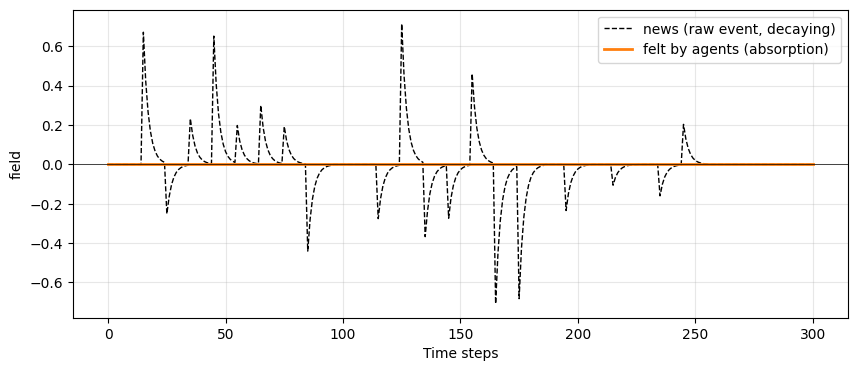

In [60]:
#Show Absorbed External Field by Agents
plt.figure(figsize=(10, 4))
plt.plot(h_ext_history,  'k--', lw=1, label='news (raw event, decaying)')
plt.plot(h_felt_history, color='tab:orange', lw=2, label='felt by agents (absorption)')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel('Time steps'); plt.ylabel('field'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

__GRAPHS SECTION__

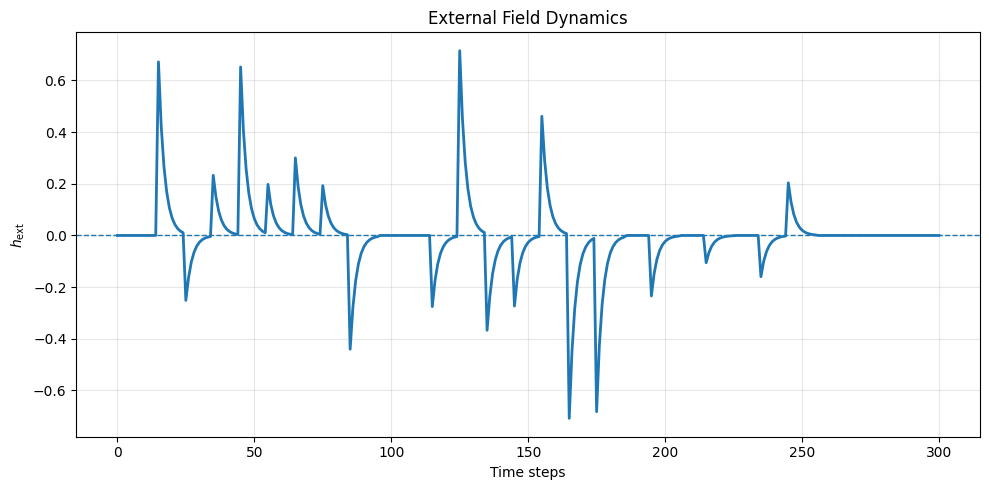

In [61]:
#PLOT EXTERNAL FIELD EVENTS
time = np.arange(len(h_ext_history))
plt.figure(figsize=(10, 5))
plt.plot(
    time,
    h_ext_history,
    linewidth=2
)
plt.axhline(
    0,
    linestyle='--',
    linewidth=1
)
plt.xlabel("Time steps")
plt.ylabel(r"$h_{\mathrm{ext}}$")
plt.title("External Field Dynamics")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

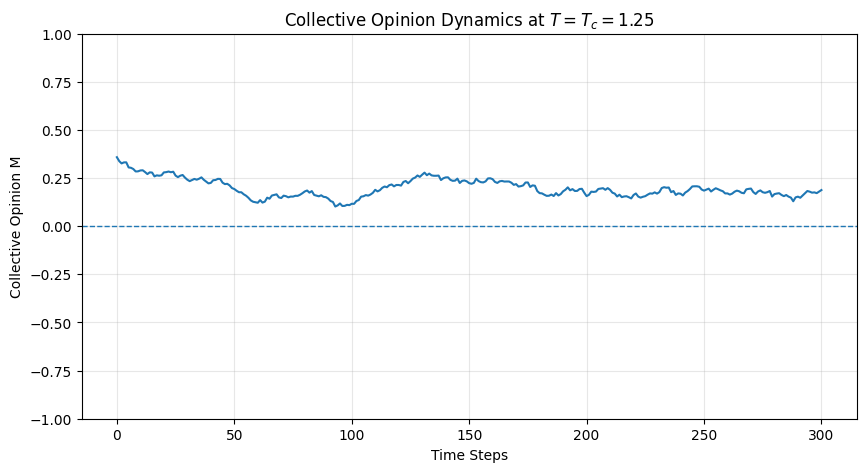

In [62]:
# PLOT COLLECTIVE OPINION (M) OVER TIME
plt.figure(figsize=(10, 5))
plt.plot(M_history)
plt.axhline(
    0,
    linestyle='--',
    linewidth=1
)
plt.xlabel("Time Steps")
plt.ylabel("Collective Opinion M")
plt.title(f"Collective Opinion Dynamics at $T=T_c={Temperature}$")
plt.ylim(-1,1)
plt.grid(alpha=0.3)
plt.show()

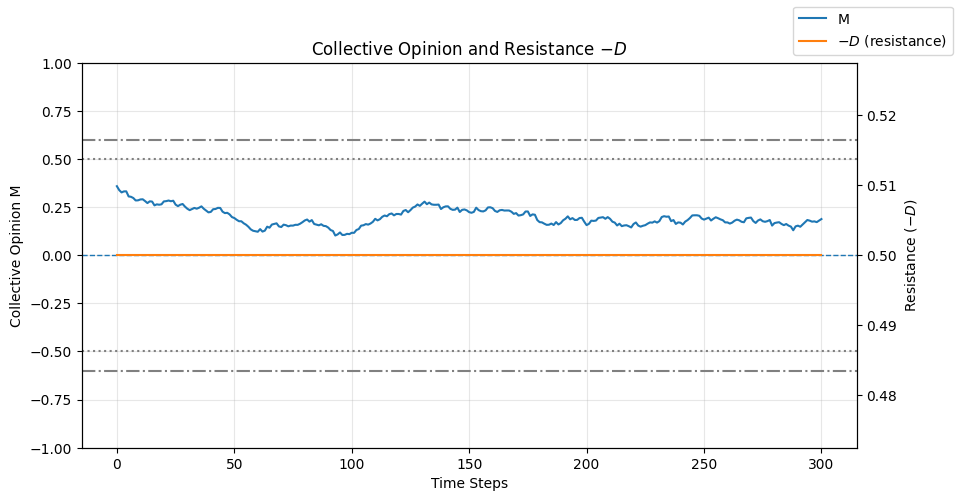

In [63]:
# PLOT M TOGETHER WITH THE ACTIVE RESISTANCE (-D)
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(M_history, label="M")
for thr in (M_low, -M_low):
    ax1.axhline(thr, linestyle=':', color='gray')
for thr in (M_high, -M_high):
    ax1.axhline(thr, linestyle='-.', color='gray')
ax1.axhline(0, linestyle='--', linewidth=1)
ax1.set_ylim(-1, 1)
ax1.set_xlabel("Time Steps")
ax1.set_ylabel("Collective Opinion M")

ax2 = ax1.twinx()
ax2.step(range(len(D_history)), -np.array(D_history), where='post',
         color='tab:orange', label=r"$-D$ (resistance)")
ax2.set_ylabel(r"Resistance $(-D)$")

fig.legend(loc="upper right")
plt.title(r"Collective Opinion and Resistance $-D$")
ax1.grid(alpha=0.3)
plt.show()

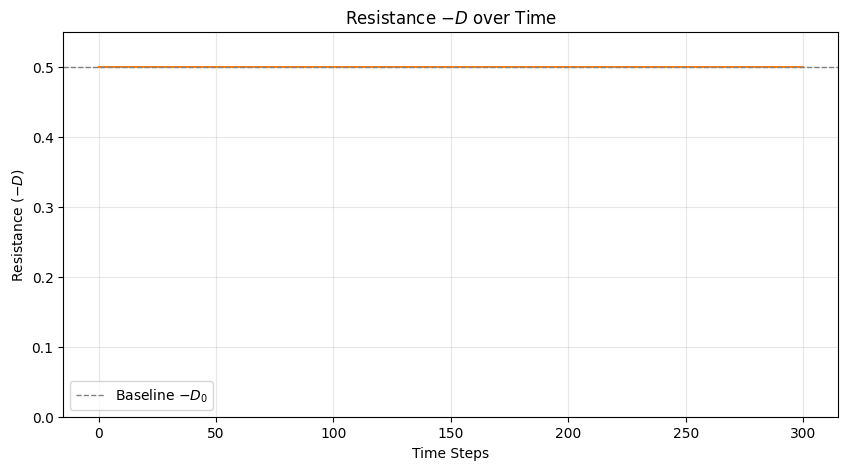

In [64]:
# PLOT ONLY THE ACTIVE RESISTANCE (-D)
minus_D = -np.array(D_history)

plt.figure(figsize=(10, 5))
plt.step(range(len(minus_D)), minus_D, where='post', color='tab:orange')
plt.axhline(-D_initial, linestyle='--', color='gray', linewidth=1,
            label=r"Baseline $-D_0$")
plt.xlabel("Time Steps")
plt.ylabel(r"Resistance $(-D)$")
plt.title(r"Resistance $-D$ over Time")
plt.ylim(0, minus_D.max() * 1.1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

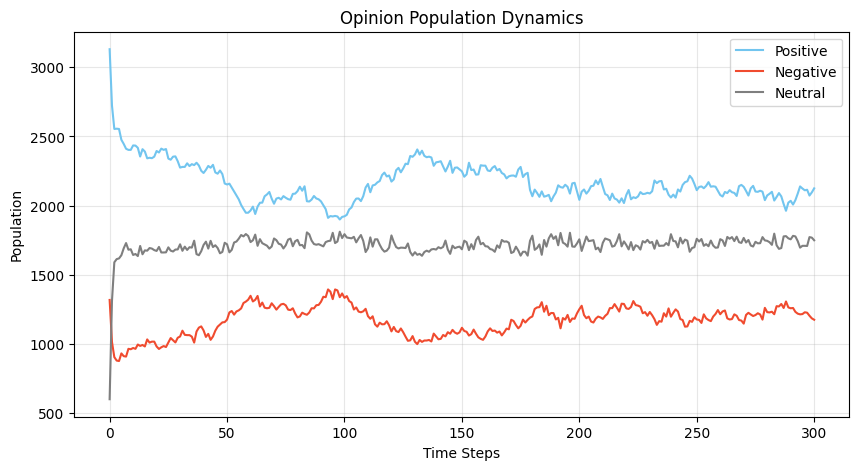

In [65]:
# PLOT OPINION POPULATION DYNAMIC OVER TIME
plt.figure(figsize=(10, 5))
plt.plot(N_up_history, color="#72C5EF", label="Positive")
plt.plot(N_down_history, color="#F04B2F", label="Negative")
plt.plot(N_neutral_history, color="#7F7F7F", label="Neutral")
plt.xlabel("Time Steps")
plt.ylabel("Population")
plt.title("Opinion Population Dynamics")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Jump up   to the locked-in branch at h + h_ext ≈ +0.089
Drop down from the locked-in branch at h + h_ext ≈ -0.099
Hysteresis width ≈ 0.188


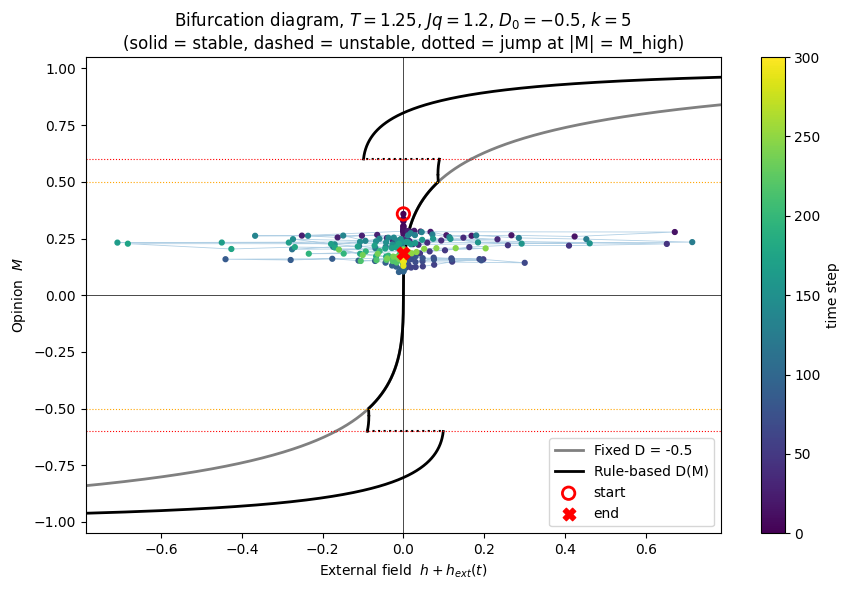

In [66]:
# ============================================================
# BIFURCATION GRAPH: M* vs external field (h + h_ext)
# + the simulated path (h + h_ext(t), M(t)) on top
# Run AFTER the simulation cell (uses Data_M, Data_h_ext)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ------------------------- SETTINGS -------------------------
T_plot   = Temperature        # temperature used in the simulation
Jq       = J_coupling * q_neighbors   # coupling J*q
Do_plot  = D_initial          # D0
k_plot   = k_sensitivity      # k in the middle band
Mlo_plot = M_low              # low-band threshold (0.5)
Mhi_plot = M_high             # high-band threshold (0.6)

lag        = 0       # shift M by a few steps if it lags behind h (try 1-3)
show_fixed = True    # draw the fixed-D reference curve (grey)
x_range    = None    # e.g. (-0.4, 0.4); None = automatic
# ------------------------------------------------------------


# ---- your D rule (same as in the model) ----
def D_rule(M):
    a = abs(M)
    if a < Mlo_plot:
        return Do_plot
    elif a <= Mhi_plot:
        return Do_plot * (1 + k_plot * (a - Mlo_plot))
    else:
        return -np.exp(abs(Do_plot) + (a - Mhi_plot))

def D_fixed(M):
    return Do_plot


# ---- single-spin response of the restricted (A-B) heat-bath model ----
def M_single(x, D, T):
    # x = beta * h_eff
    c = np.exp(-D / T)
    num = 2*c*np.sinh(x) + 2*c**2*np.sinh(2*x)
    den = 1 + 4*c*np.cosh(x) + 2*c**2*np.cosh(2*x)
    return num / den


# ---- for a given M, find the field h that makes M a steady state ----
# self-consistency: M = M_single(beta*(h + Jq*M), D(M))
# solve for x = beta*h_eff, then h = x*T - Jq*M
def h_of_M(M, D_func):
    D = D_func(M)
    x = brentq(lambda x: M_single(x, D, T_plot) - M, -40, 40)
    return x * T_plot - Jq * M


def branch(D_func):
    # split at the thresholds so the jumps in D are not joined by a line
    edges = [-0.999, -Mhi_plot, -Mlo_plot, Mlo_plot, Mhi_plot, 0.999]
    pieces = []
    for a, b in zip(edges[:-1], edges[1:]):
        Ms = np.linspace(a, b, 400)[1:-1]
        hs = np.array([h_of_M(m, D_func) for m in Ms])
        pieces.append((hs, Ms))
    return pieces


def plot_branch(ax, D_func, color, label):
    first = True
    for hs, Ms in branch(D_func):
        dh = np.gradient(hs, Ms)
        stable = dh > 0                     # stable where h increases with M
        for mask, ls in [(stable, '-'), (~stable, '--')]:
            ax.plot(np.where(mask, hs, np.nan), np.where(mask, Ms, np.nan),
                    ls, color=color, lw=2,
                    label=label if (first and ls == '-') else None)
        first = False
    # dotted horizontal links where D jumps (|M| = M_high)
    for s in [1, -1]:
        Mth = s * Mhi_plot
        h_below = h_of_M(Mth - s*1e-4, D_func)
        h_above = h_of_M(Mth + s*1e-4, D_func)
        ax.plot([h_below, h_above], [Mth, Mth], ':', color=color, lw=1.5)


# ---- print the jump points (useful for the text) ----
h_up   = h_of_M(Mhi_plot - 1e-4, D_rule)   # lower branch ends -> jump UP
h_down = h_of_M(Mhi_plot + 1e-4, D_rule)   # upper branch ends -> drop DOWN
print(f"Jump up   to the locked-in branch at h + h_ext ≈ {h_up:+.3f}")
print(f"Drop down from the locked-in branch at h + h_ext ≈ {h_down:+.3f}")
print(f"Hysteresis width ≈ {h_up - h_down:.3f}")


# ============================ PLOT ============================
fig, ax = plt.subplots(figsize=(9, 6))

if show_fixed:
    plot_branch(ax, D_fixed, 'grey', f'Fixed D = {Do_plot}')
plot_branch(ax, D_rule, 'black', 'Rule-based D(M)')

# ---- simulated path ----
H     = External_field + np.array(h_ext_history, dtype=float)   # total external field h + h_ext
M_sim = np.array(M_history, dtype=float)
n = min(len(H), len(M_sim))
H, M_sim = H[:n], M_sim[:n]
if lag > 0:
    H, M_sim = H[:-lag], M_sim[lag:]
steps = np.arange(len(H))

ax.plot(H, M_sim, '-', color='tab:blue', lw=0.6, alpha=0.35)
sc = ax.scatter(H, M_sim, c=steps, cmap='viridis', s=12, zorder=3)
ax.scatter(H[0], M_sim[0], marker='o', s=80, facecolors='none',
           edgecolors='red', lw=2, zorder=4, label='start')
ax.scatter(H[-1], M_sim[-1], marker='X', s=80, color='red', zorder=4, label='end')
plt.colorbar(sc, ax=ax, label='time step')

# reference lines
ax.axhline(0, color='k', lw=0.5)
ax.axvline(0, color='k', lw=0.5)
for s in [1, -1]:
    ax.axhline(s*Mlo_plot, color='orange', lw=0.8, ls=':')
    ax.axhline(s*Mhi_plot, color='red',    lw=0.8, ls=':')

if x_range is None:
    hx = max(0.4, np.nanmax(np.abs(H)) * 1.1)
    x_range = (-hx, hx)
ax.set_xlim(*x_range)
ax.set_ylim(-1.05, 1.05)
ax.set_xlabel(r'External field  $h + h_{ext}(t)$')
ax.set_ylabel(r'Opinion  $M$')
ax.set_title(rf'Bifurcation diagram, $T={T_plot}$, $Jq={Jq}$, '
             rf'$D_0={Do_plot}$, $k={k_plot}$'
             '\n(solid = stable, dashed = unstable, dotted = jump at |M| = M_high)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

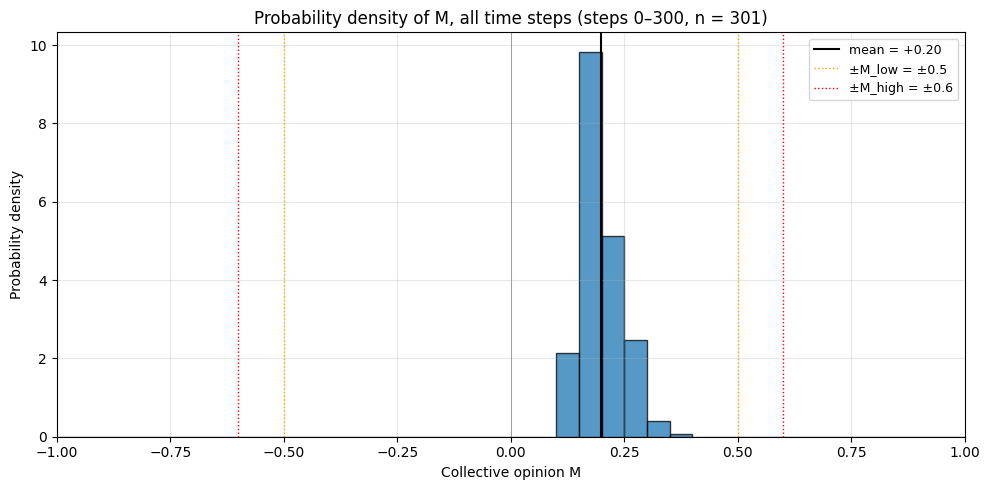

mean = +0.198, std = 0.047, min = +0.10, max = +0.36
time spent with M > +0.6: 0%,  |M| <= 0.6: 100%,  M < -0.6: 0%


In [67]:
# ============================================================
# PROBABILITY DENSITY OF ALL TIME STEPS
# Uses M_history, N_up_history, N_neutral_history, N_down_history from your run
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

# ------------------------- SETTINGS -------------------------
variable   = 'M'        # 'M' = collective opinion, 'p0' = share of neutrals
n_bins     = 40
step_start = 0          # first time step to include (e.g. 20 to skip the start-up)
step_end   = None       # last time step to include (None = until the end)
bar_color  = 'tab:blue'
# ------------------------------------------------------------

N_tot = np.array(N_up_history) + np.array(N_neutral_history) + np.array(N_down_history)
data = {'M':  np.array(M_history, dtype=float),
        'p0': np.array(N_neutral_history) / N_tot}[variable]
last = len(data) - 1 if step_end is None else min(step_end, len(data) - 1)
x_all = data[step_start:last + 1]

x_range = (-1, 1) if variable == 'M' else (0, 1)
bins = np.linspace(*x_range, n_bins + 1)
xlabel = 'Collective opinion M' if variable == 'M' else 'Share of neutrals p(0)'

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(x_all, bins=bins, density=True, color=bar_color, alpha=0.75, edgecolor='k', lw=0.3)
ax.axvline(x_all.mean(), color='k', lw=1.5, label=f'mean = {x_all.mean():+.2f}')

# reference lines: band thresholds
if variable == 'M':
    for s in [1, -1]:
        ax.axvline(s * M_low,  color='orange', ls=':', lw=1,
                   label=f'±M_low = ±{M_low}' if s == 1 else None)
        ax.axvline(s * M_high, color='red',    ls=':', lw=1,
                   label=f'±M_high = ±{M_high}' if s == 1 else None)
    ax.axvline(0, color='grey', lw=0.5)

ax.set_xlim(*x_range)
ax.set_xlabel(xlabel)
ax.set_ylabel('Probability density')
ax.set_title(f'Probability density of {variable}, all time steps '
             f'(steps {step_start}–{last}, n = {len(x_all)})')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---- numbers for the text ----
print(f"mean = {x_all.mean():+.3f}, std = {x_all.std():.3f}, "
      f"min = {x_all.min():+.2f}, max = {x_all.max():+.2f}")
if variable == 'M':
    print(f"time spent with M > +{M_high}: {np.mean(x_all > M_high):.0%},  "
          f"|M| <= {M_high}: {np.mean(np.abs(x_all) <= M_high):.0%},  "
          f"M < -{M_high}: {np.mean(x_all < -M_high):.0%}")

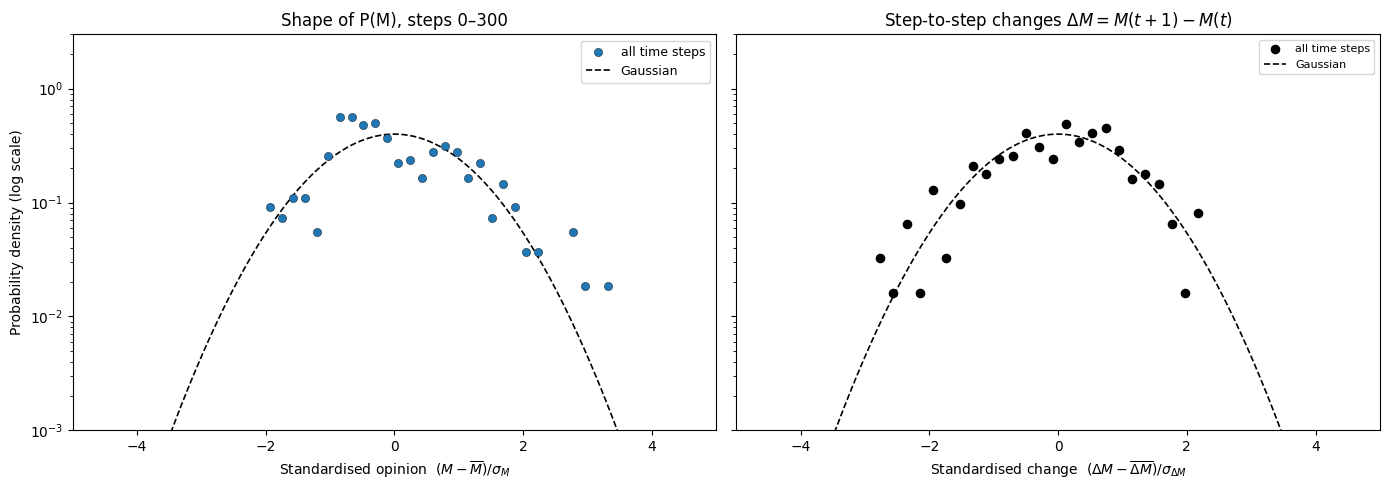

        n    mean    std   skew  ex.kurt
M     301  +0.198  0.047  +0.60    +0.08
dM    300  -0.001  0.010  -0.30    -0.16
largest |dM| = 0.029 between steps 278 and 279 (2.9 std)


In [68]:
# ============================================================
# DISTRIBUTION SHAPE AS SCATTER (log scale) + GAUSSIAN REFERENCE, ALL TIME STEPS
# Left : P(M) of all time steps, standardised  z = (M - mean)/std
# Right: P(dM) of the step-to-step changes dM = M(t+1) - M(t), standardised
#        -> this is where heavy tails (big sudden jumps) show up
# Dashed line = standard normal (Gaussian). Dots above it far from 0 = heavier tails.
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ------------------------- SETTINGS -------------------------
step_start = 0        # first time step to include (e.g. 20 to skip the start-up)
step_end   = None     # last time step to include (None = until the end)
n_bins_M   = 30
n_bins_dM  = 25
z_lim      = None     # x-range in standard deviations (None = automatic, shows all points)
big_jump   = 3        # mark changes larger than this many standard deviations
# ------------------------------------------------------------

M_all = np.array(M_history, dtype=float)
last  = len(M_all) - 1 if step_end is None else min(step_end, len(M_all) - 1)
M_arr = M_all[step_start:last + 1]

def density_points(x, bins):
    p, edges = np.histogram(x, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    keep = p > 0                      # log scale: drop empty bins
    return centers[keep], p[keep]

def standardise(x):
    return (x - x.mean()) / x.std()

zM = standardise(M_arr)
dM = np.diff(M_arr)                   # dM[i] = M(i+1) - M(i)
z  = standardise(dM)
if z_lim is None:
    z_lim = max(5, np.ceil(max(np.abs(zM).max(), np.abs(z).max())) + 0.5)
zs = np.linspace(-z_lim, z_lim, 400)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# ---- left: shape of P(M), all time steps ----
c, p = density_points(zM, np.linspace(zM.min(), zM.max(), n_bins_M + 1))
axL.scatter(c, p, color='tab:blue', s=35, edgecolors='k', lw=0.3, zorder=3, label='all time steps')
axL.plot(zs, stats.norm.pdf(zs), 'k--', lw=1.2, label='Gaussian')
axL.set_yscale('log'); axL.set_ylim(1e-3, 3); axL.set_xlim(-z_lim, z_lim)
axL.set_xlabel(r'Standardised opinion  $(M - \overline{M})/\sigma_M$')
axL.set_ylabel('Probability density (log scale)')
axL.set_title(f'Shape of P(M), steps {step_start}–{last}')
axL.legend(fontsize=9)

# ---- right: step-to-step changes, all time steps ----
c, p = density_points(z, np.linspace(z.min(), z.max(), n_bins_dM + 1))
axR.scatter(c, p, color='k', s=35, zorder=3, label='all time steps')
axR.plot(zs, stats.norm.pdf(zs), 'k--', lw=1.2, label='Gaussian')
# mark the big jumps and write the time step next to them
big = np.where(np.abs(z) > big_jump)[0]
if len(big):
    axR.scatter(z[big], np.full(len(big), 2e-3), marker='|', s=300, color='tab:red',
                lw=2, label=f'|z| > {big_jump} ({len(big)} steps)')
    for i in big:
        axR.annotate(str(step_start + i + 1), (z[i], 2e-3), textcoords='offset points',
                     xytext=(0, 10), fontsize=7, ha='center', rotation=90)
axR.set_xlim(-z_lim, z_lim)
axR.set_xlabel(r'Standardised change  $(\Delta M - \overline{\Delta M})/\sigma_{\Delta M}$')
axR.set_title(r'Step-to-step changes $\Delta M = M(t+1) - M(t)$')
axR.legend(fontsize=8)

plt.tight_layout(); plt.show()

# ---- numbers for the text ----
# excess kurtosis: 0 = Gaussian, > 0 = heavier tails, < 0 = lighter tails / flatter
print(f"{'':4s} {'n':>4s} {'mean':>7s} {'std':>6s} {'skew':>6s} {'ex.kurt':>8s}")
print(f"M    {len(M_arr):4d} {M_arr.mean():+7.3f} {M_arr.std():6.3f} "
      f"{stats.skew(M_arr):+6.2f} {stats.kurtosis(M_arr):+8.2f}")
print(f"dM   {len(dM):4d} {dM.mean():+7.3f} {dM.std():6.3f} "
      f"{stats.skew(dM):+6.2f} {stats.kurtosis(dM):+8.2f}")
k = np.argmax(np.abs(dM))
print(f"largest |dM| = {abs(dM[k]):.3f} between steps {step_start + k} and {step_start + k + 1} "
      f"({abs(z[k]):.1f} std)")
if len(big):
    print(f"steps with |z| > {big_jump}: {(step_start + big + 1).tolist()}")

__COMPARISON__

In [69]:
# ============================================================
# RUN ALL D-VARIATIONS AND STORE THE RESULTS at Tc
# ============================================================
import numpy as np

# events file used for this comparison (generate it first with your generator cell)
events_used = np.load("raw_external_field58h075.npy").tolist()

# what differs between runs -> (D_initial, M_low, M_high)
# fixed D: put the band thresholds out of reach (2.0), so D always stays = D_initial
conditions = {
    'D = 0':        dict(D0=0.0,  M_low=2.0, M_high=2.0, T=1.029),   # own Tc for D = 0
    'D = -0.5':     dict(D0=-0.5, M_low=2.0, M_high=2.0, T=1.25),
    'D rule-based': dict(D0=-0.5, M_low=0.5, M_high=0.6, T=1.25),
}

all_results = {}
for name, c in conditions.items():
    print(f"--- running {name} ---")
    np.random.seed(42)                       # SAME seed for every condition -> fair comparison
    res = simulate_open_population(N_up_initial, N_down_initial, N_o, c['T'], External_field,
                                   J_coupling, q_neighbors, c['D0'], k_sensitivity, r_growth,
                                   Time_steps, events_used,
                                   M_low=c['M_low'], M_high=c['M_high'], dt=1.0)
    (N_up_h, N_down_h, N_0_h, M_h, N_tot_h, h_ext_h, h_eff_h, D_h, _, _, h_felt_h) = res
    all_results[name] = dict(M=np.array(M_h), N_up=np.array(N_up_h), N_down=np.array(N_down_h),
                             N_0=np.array(N_0_h), D=np.array(D_h),
                             h_ext=np.array(h_ext_h), h_felt=np.array(h_felt_h),
                             T=c['T'])
# optional but recommended: save to a file so you don't lose the runs if Colab disconnects
np.save("results_D_variationh0.npy", all_results, allow_pickle=True)

--- running D = 0 ---
MCS 10/300 selesai | N = 5051
MCS 20/300 selesai | N = 5051
MCS 30/300 selesai | N = 5051
MCS 40/300 selesai | N = 5051
MCS 50/300 selesai | N = 5051
MCS 60/300 selesai | N = 5051
MCS 70/300 selesai | N = 5051
MCS 80/300 selesai | N = 5051
MCS 90/300 selesai | N = 5051
MCS 100/300 selesai | N = 5051
MCS 110/300 selesai | N = 5051
MCS 120/300 selesai | N = 5051
MCS 130/300 selesai | N = 5051
MCS 140/300 selesai | N = 5051
MCS 150/300 selesai | N = 5051
MCS 160/300 selesai | N = 5051
MCS 170/300 selesai | N = 5051
MCS 180/300 selesai | N = 5051
MCS 190/300 selesai | N = 5051
MCS 200/300 selesai | N = 5051
MCS 210/300 selesai | N = 5051
MCS 220/300 selesai | N = 5051
MCS 230/300 selesai | N = 5051
MCS 240/300 selesai | N = 5051
MCS 250/300 selesai | N = 5051
MCS 260/300 selesai | N = 5051
MCS 270/300 selesai | N = 5051
MCS 280/300 selesai | N = 5051
MCS 290/300 selesai | N = 5051
MCS 300/300 selesai | N = 5051
--- running D = -0.5 ---
MCS 10/300 selesai | N = 5051
MC

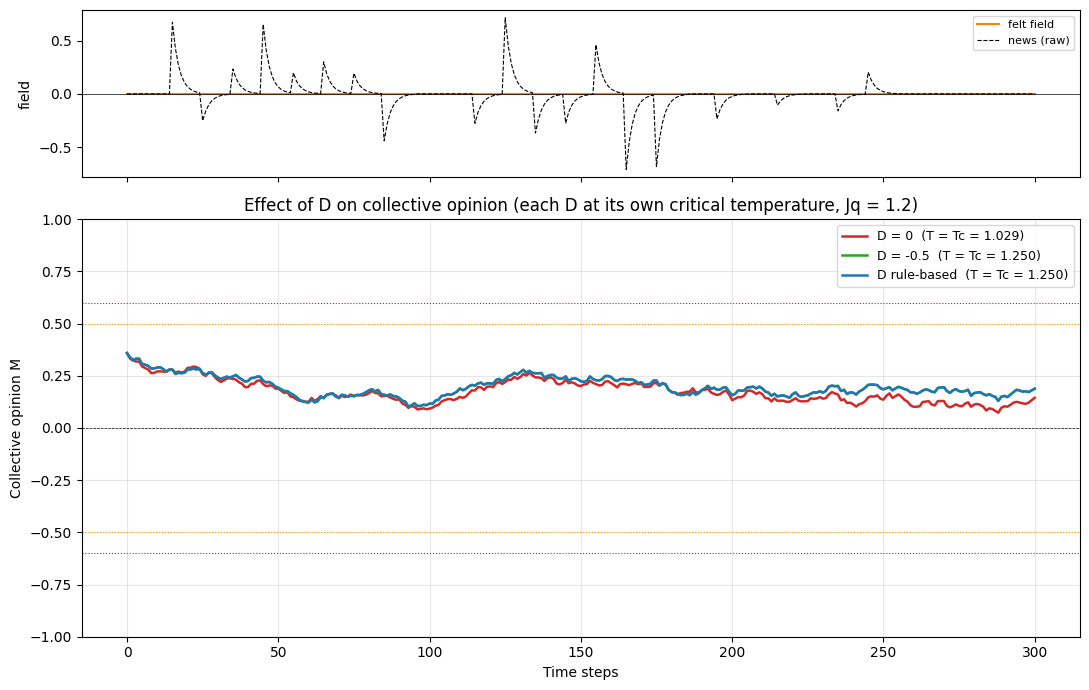

In [70]:
# ============================================================
# PLOT: M(t) for all D-variations, each D at its own critical temperature
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

all_results = np.load("results_D_variationh0.npy", allow_pickle=True).item()

colors = {'D = 0': 'tab:red', 'D = -0.5': 'tab:green', 'D rule-based': 'tab:blue'}

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={'height_ratios': [1, 2.5]})

# top: the felt field (the same for every condition)
first = next(iter(all_results.values()))
ax0.plot(first['h_felt'], color='tab:orange', lw=1.5, label='felt field')
ax0.plot(first['h_ext'], 'k--', lw=0.8, label='news (raw)')
ax0.axhline(0, color='k', lw=0.5); ax0.set_ylabel('field'); ax0.legend(fontsize=8)

# bottom: M(t) of every condition, with its own T in the legend
for name, r in all_results.items():
    ax1.plot(r['M'], color=colors.get(name), lw=1.8, label=f"{name}  (T = Tc = {r['T']:.3f})")
for s in [1, -1]:
    ax1.axhline(s * M_low,  color='orange', ls=':', lw=0.8)
    ax1.axhline(s * M_high, color='red',    ls=':', lw=0.8)
ax1.axhline(0, color='k', ls='--', lw=0.5)
ax1.set_ylim(-1, 1); ax1.set_xlabel('Time steps'); ax1.set_ylabel('Collective opinion M')
ax1.set_title(f'Effect of D on collective opinion (each D at its own critical temperature, Jq = {J_coupling*q_neighbors})')
ax1.legend(fontsize=9); ax1.grid(alpha=0.3)
plt.tight_layout(); plt.show()

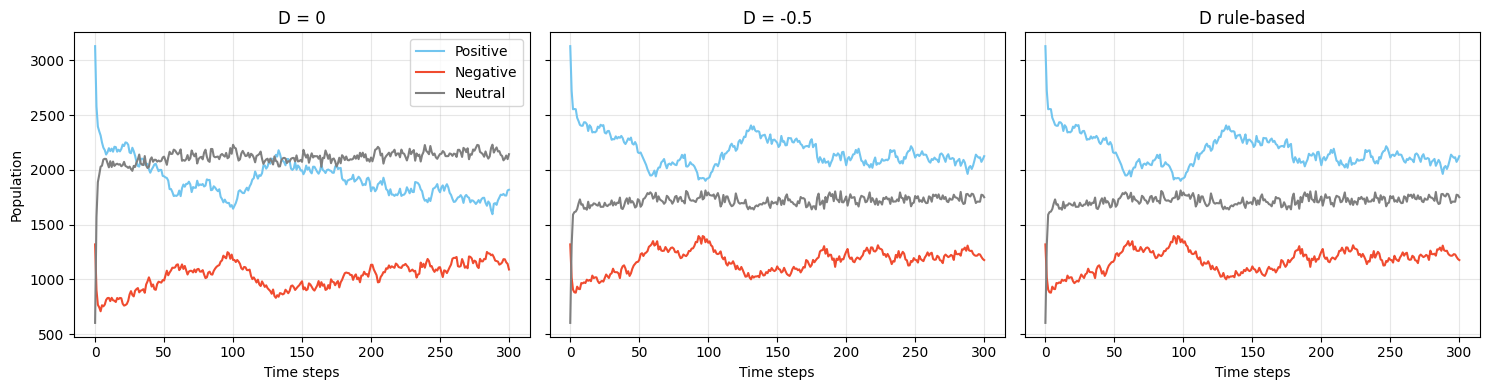

In [71]:
fig, axes = plt.subplots(1, len(all_results), figsize=(5 * len(all_results), 4), sharey=True)
for ax, (name, r) in zip(axes, all_results.items()):
    ax.plot(r['N_up'], color="#72C5EF", label='Positive')
    ax.plot(r['N_down'], color="#F04B2F", label='Negative')
    ax.plot(r['N_0'], color="#7F7F7F", label='Neutral')
    ax.set_title(name); ax.set_xlabel('Time steps'); ax.grid(alpha=0.3)
axes[0].set_ylabel('Population'); axes[0].legend()
plt.tight_layout(); plt.show()

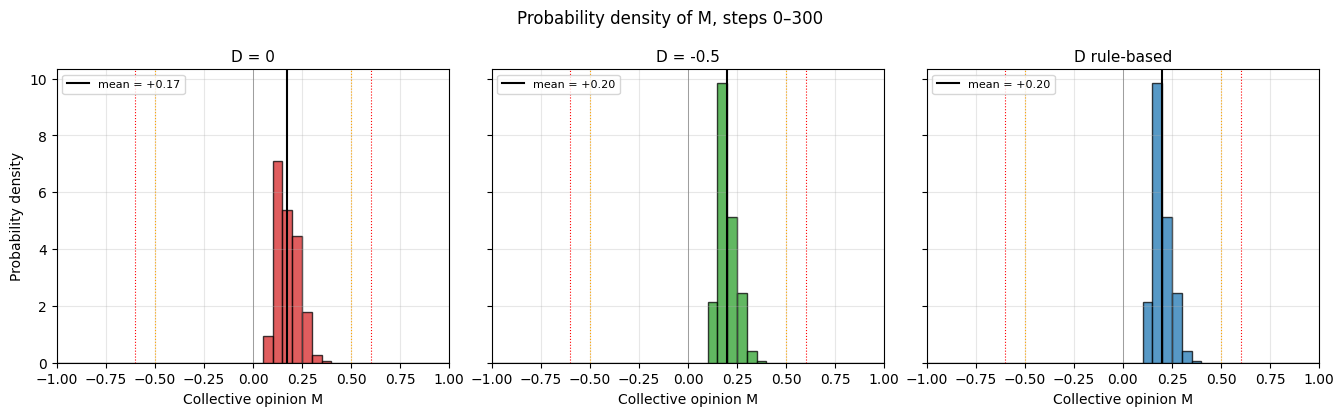

condition           mean    std   kurt |  M>+0.6 |M|<=0.6  M<-0.6
D = 0             +0.174  0.055  -0.17 |      0%     100%      0%
D = -0.5          +0.198  0.047  +0.08 |      0%     100%      0%
D rule-based      +0.198  0.047  +0.08 |      0%     100%      0%


In [72]:
# ============================================================
# COMPARE PROBABILITY DISTRIBUTIONS OF M BETWEEN CONDITIONS
# One histogram panel per condition (side by side, same axes)
# Works for any saved experiment file (D-, T- or event-variation)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ------------------------- SETTINGS -------------------------
results_file = "results_D_variationh0.npy"   # which experiment to show
step_start   = 0          # skip the start-up if you want (e.g. 20)
n_bins       = 40
colors = {'D = 0': 'tab:red', 'D = -0.5': 'tab:green', 'D rule-based': 'tab:blue'}  # None -> default colours
# ------------------------------------------------------------

all_results = np.load(results_file, allow_pickle=True).item()
names = list(all_results.keys())
bins = np.linspace(-1, 1, n_bins + 1)
default_cols = plt.rcParams['axes.prop_cycle'].by_key()['color']

fig, axes = plt.subplots(1, len(names), figsize=(4.5 * len(names), 4.2), sharex=True, sharey=True)
axes = np.atleast_1d(axes)

for j, (ax, name) in enumerate(zip(axes, names)):
    M = all_results[name]['M'][step_start:]
    col = colors.get(name) if colors else default_cols[j % len(default_cols)]

    ax.hist(M, bins=bins, density=True, color=col, alpha=0.75, edgecolor='k', lw=0.3)
    ax.axvline(M.mean(), color='k', lw=1.5, label=f'mean = {M.mean():+.2f}')

    # band thresholds
    for s in [1, -1]:
        ax.axvline(s * 0.5, color='orange', ls=':', lw=0.8)
        ax.axvline(s * 0.6, color='red', ls=':', lw=0.8)
    ax.axvline(0, color='grey', lw=0.5)

    ax.set_xlim(-1, 1)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('Collective opinion M')
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Probability density')
n_steps = len(all_results[names[0]]['M']) - 1
fig.suptitle(f'Probability density of M, steps {step_start}–{n_steps}')
plt.tight_layout(); plt.show()

# ---- numbers for the text ----
print(f"{'condition':16s} {'mean':>7s} {'std':>6s} {'kurt':>6s} | {'M>+0.6':>7s} {'|M|<=0.6':>8s} {'M<-0.6':>7s}")
for name in names:
    M = all_results[name]['M'][step_start:]
    print(f"{name:16s} {M.mean():+7.3f} {M.std():6.3f} {stats.kurtosis(M):+6.2f} | "
          f"{np.mean(M > 0.6):7.0%} {np.mean(np.abs(M) <= 0.6):8.0%} {np.mean(M < -0.6):7.0%}")

In [73]:
# ============================================================
# BIFURCATION COMPARISON FOR THE D-VARIATION, EACH D AT ITS OWN Tc
# Left : M vs h  - theory branches of each D condition at ITS OWN T + simulated paths
# Right: M vs D  - fixed-D theory at h = 0, drawn at each temperature used,
#                  + the rule D(M) + simulated (D, M) points
# Uses: compute_D, the parameters (J_coupling, q_neighbors, D_initial, k_sensitivity,
#       M_low, M_high, External_field) and the saved results file (which stores T)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ------------------------- SETTINGS -------------------------
results_file = "results_D_variation.npy"
Jq = J_coupling * q_neighbors
# D setting of every condition: ('fixed', D value) or ('rule', None)  -> must match the run cell
D_settings = {
    'D = 0':        ('fixed', 0.0),
    'D = -0.5':     ('fixed', -0.5),
    'D rule-based': ('rule',  None),
}
colors = {'D = 0': 'tab:olive', 'D = -0.5': 'tab:grey', 'D rule-based': 'tab:blue'}
show_paths = True          # draw the simulated paths on top of the theory
h_range    = (-0.6, 0.6)   # x-range of the M vs h panel
D_range    = (-3.0, 2.0)   # x-range of the M vs D panel
# ------------------------------------------------------------

all_results = np.load(results_file, allow_pickle=True).item()

def D_func_of(setting):
    kind, val = setting
    if kind == 'fixed':
        return lambda M: val
    return lambda M: compute_D(M, D_initial, k_sensitivity, M_low, M_high)

# single-spin response of the restricted (A-B) heat-bath model, x = h_eff / T
def M_single(x, D, T):
    c = np.exp(-D / T)
    return (2*c*np.sinh(x) + 2*c**2*np.sinh(2*x)) / (1 + 4*c*np.cosh(x) + 2*c**2*np.cosh(2*x))

# ---------- M vs h: for every M, the field h that makes M a steady state at temperature T ----------
def h_of_M(M, D, T):
    x = brentq(lambda x: M_single(x, D, T) - M, -40, 40)
    return x * T - Jq * M

def plot_h_branches(ax, D_func, T, color, label):
    edges = [-0.999, -M_high, -M_low, M_low, M_high, 0.999]     # split where the rule jumps
    first = True
    for a, b in zip(edges[:-1], edges[1:]):
        Ms = np.linspace(a, b, 300)[1:-1]
        hs = np.array([h_of_M(m, D_func(m), T) for m in Ms])
        stable = np.gradient(hs, Ms) > 0                          # stable where h rises with M
        for mask, ls in [(stable, '-'), (~stable, '--')]:
            ax.plot(np.where(mask, hs, np.nan), np.where(mask, Ms, np.nan), ls, color=color, lw=2,
                    label=label if (first and ls == '-') else None)
        first = False

# ---------- M vs D: steady states at h = 0 for a FIXED D, at temperature T ----------
def D_of_M(M, T):
    # the fixed D that makes M (> 0) a steady state at h = 0 (nan if no D can do it)
    f = lambda D: M_single(Jq * M / T, D, T) - M
    try:
        return brentq(f, -30, 10)
    except ValueError:
        return np.nan

def is_stable(M, D, T, eps=1e-4):
    slope = (M_single(Jq*(M+eps)/T, D, T) - M_single(Jq*(M-eps)/T, D, T)) / (2*eps)
    return slope < 1

def plot_pitchfork(ax, T, color, label):
    Ms = np.linspace(0.005, 0.995, 400)
    Ds = np.array([D_of_M(m, T) for m in Ms])
    st = np.array([is_stable(m, d, T) if np.isfinite(d) else False for m, d in zip(Ms, Ds)])
    D_c = D_of_M(1e-3, T)                                     # where the ordered branch starts
    for sign in [1, -1]:
        for mask, ls in [(st, '-'), (~st, '--')]:
            ax.plot(np.where(mask, Ds, np.nan), sign * np.where(mask, Ms, np.nan), ls, color=color, lw=2,
                    label=label if (sign == 1 and ls == '-') else None)
    ax.plot([D_c, D_range[1]], [0, 0], '-', color=color, lw=2)     # M = 0 stable for D above D_c
    ax.plot([D_range[0], D_c], [0, 0], '--', color=color, lw=2)    # M = 0 unstable for D below D_c
    ax.axvline(D_c, color=color, ls=':', lw=0.8)
    return D_c

fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 6))

# ======================= LEFT: M vs h (each D at its own T) =======================
for name, setting in D_settings.items():
    if name not in all_results:
        continue
    r = all_results[name]
    T = r['T']
    plot_h_branches(axL, D_func_of(setting), T, colors[name], f'{name}, T = {T:.3f} (theory)')
    if show_paths:
        H = External_field + np.asarray(r['h_felt'], dtype=float)
        axL.plot(H, r['M'], '-', color=colors[name], lw=0.7, alpha=0.45)
        axL.scatter(H, r['M'], color=colors[name], s=6, alpha=0.5)
for s in [1, -1]:
    axL.axhline(s * M_low, color='orange', ls=':', lw=0.8)
    axL.axhline(s * M_high, color='red', ls=':', lw=0.8)
axL.axhline(0, color='k', lw=0.5); axL.axvline(0, color='k', lw=0.5)
axL.set_xlim(*h_range); axL.set_ylim(-1.05, 1.05)
axL.set_xlabel(r'Felt external field  $h + h_{felt}$'); axL.set_ylabel('Collective opinion M')
axL.set_title(f'M vs h, each D at its own Tc  (Jq = {Jq})\nsolid = stable, dashed = unstable, dots = simulation')
axL.legend(fontsize=8, loc='lower right'); axL.grid(alpha=0.3)

# ======================= RIGHT: M vs D =======================
# one fixed-D pitchfork for every temperature that was used
T_used = sorted({round(float(r['T']), 4) for r in all_results.values()})
Dc_text = []
for T in T_used:
    # colour the pitchfork like the condition that ran at this T, black if several share it
    names_T = [n for n, r in all_results.items() if round(float(r['T']), 4) == T]
    col = colors[names_T[0]] if len(names_T) == 1 else 'k'
    D_c = plot_pitchfork(axR, T, col, f'fixed-D theory at T = {T:.3f}')
    Dc_text.append(f'T = {T:.3f}: D_c = {D_c:.2f}')

# the rule D(M) (belongs to the temperature of the rule-based run)
Mr = np.linspace(-0.999, 0.999, 2001)
Dr = np.array([compute_D(m, D_initial, k_sensitivity, M_low, M_high) for m in Mr])
Dr[1:][np.abs(np.diff(Dr)) > 0.05] = np.nan          # do not draw a line across the jumps of the rule
axR.plot(Dr, Mr, color=colors.get('D rule-based', 'tab:blue'), lw=1.2, ls='-.', label='rule D(M)')

# simulated (D, M) points of every condition
if show_paths:
    for name, r in all_results.items():
        axR.scatter(r['D'], r['M'], color=colors.get(name), s=8, alpha=0.5,
                    label=f"{name} (simulation, T = {r['T']:.3f})")

axR.set_xlim(-0.5, 1.0); axR.set_ylim(-1.05, 1.05)
axR.set_xlabel('Resistance parameter D'); axR.set_ylabel('Collective opinion M')
axR.set_title('M vs D at h = 0, pitchfork drawn at each temperature used\n' + ',   '.join(Dc_text))
axR.legend(fontsize=7, loc='lower left'); axR.grid(alpha=0.3)

plt.tight_layout(); plt.show()
for t in Dc_text:
    print(f"fixed D: ordered states (M != 0) exist for D < D_c at {t}")

FileNotFoundError: [Errno 2] No such file or directory: 'results_D_variation.npy'

In [75]:
# ============================================================
# STATISTICS CELL 0: load one experiment (same news seed) + its event file
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

# ------------------------- SETTINGS -------------------------
results_file = "results_D_variationh075.npy"        # results of ONE news seed (e.g. seed 58)
events_file  = "raw_external_field58h075.npy"       # the event file used for those runs
results_h0   = "results_D_variationh0.npy"     # the same conditions with NO news (h_felt = 0); None if you don't have it
colors = {'D = 0': 'tab:red', 'D = -0.5': 'tab:green', 'D rule-based': 'tab:blue'}
N_pop  = 5051                                   # population size (N_up_initial + N_down_initial + N_o)
T_default = 1.25                                # used when a result has no stored 'T'
# ------------------------------------------------------------

R  = np.load(results_file, allow_pickle=True).item()
R0 = np.load(results_h0, allow_pickle=True).item() if results_h0 else None
events = np.load(events_file)                   # columns: day, amplitude, fade_days
events = events[events[:, 1] != 0]              # neutral (zero-amplitude) events carry no news
names  = list(R.keys())
print("conditions:", names)
print(f"{len(events)} non-zero events, last one on day {int(events[:, 0].max())}")

def band_of(m):
    a = abs(m)
    return 'low (|M|<0.5)' if a < 0.5 else ('middle (0.5-0.6)' if a <= 0.6 else 'top (|M|>0.6)')

conditions: ['D = 0', 'D = -0.5', 'D rule-based']
19 non-zero events, last one on day 245


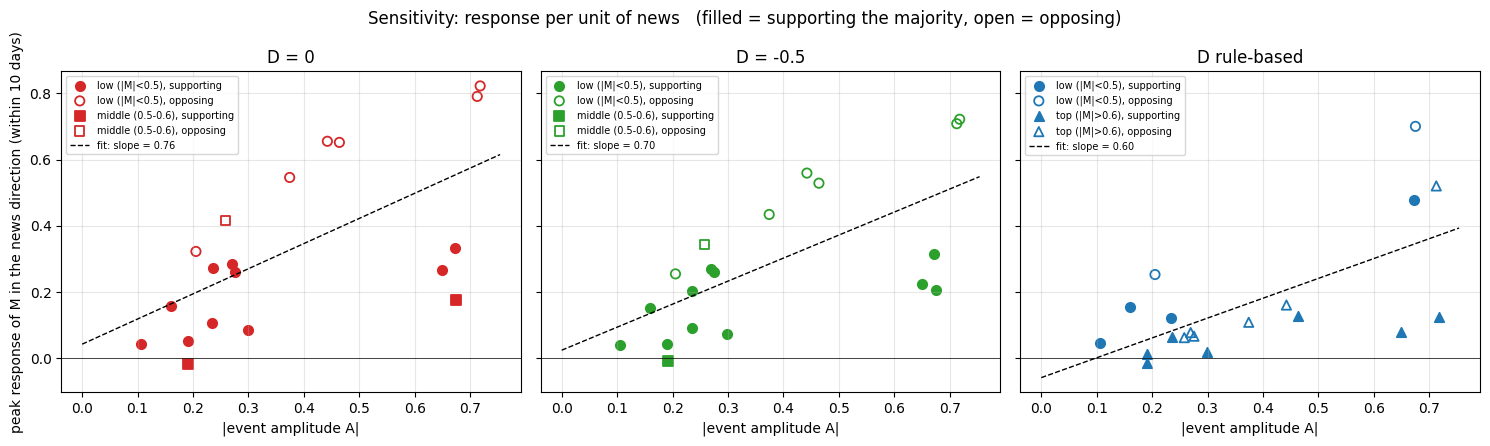

condition       band               relation      n mean peak   slope
D = 0           low (|M|<0.5)      supporting   10     0.186    0.37
D = 0           low (|M|<0.5)      opposing      6     0.632    0.88
D = 0           middle (0.5-0.6)   supporting    2     0.081     nan
D = 0           middle (0.5-0.6)   opposing      1     0.417     nan
D = -0.5        low (|M|<0.5)      supporting   11     0.171    0.27
D = -0.5        low (|M|<0.5)      opposing      6     0.535    0.86
D = -0.5        middle (0.5-0.6)   supporting    1    -0.009     nan
D = -0.5        middle (0.5-0.6)   opposing      1     0.344     nan
D rule-based    low (|M|<0.5)      supporting    4     0.200    0.72
D rule-based    low (|M|<0.5)      opposing      2     0.477     nan
D rule-based    top (|M|>0.6)      supporting    7     0.060    0.20
D rule-based    top (|M|>0.6)      opposing      6     0.166    0.99


In [76]:
# ============================================================
# STATISTICS CELL 1: SENSITIVITY - response per unit of news
# for every event: peak response of M in the direction of the news, vs |amplitude|
# ============================================================
window = 10          # days after the event in which the peak is searched (= event spacing)

band_markers = {'low (|M|<0.5)': 'o', 'middle (0.5-0.6)': 's', 'top (|M|>0.6)': '^'}
rows = []
fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 4.5), sharey=True)
axes = np.atleast_1d(axes)
for ax, name in zip(axes, names):
    M = np.asarray(R[name]['M'], dtype=float)
    pts = []
    for day, A, fade in events:
        t0 = int(day)
        if t0 + window >= len(M):
            continue
        s = np.sign(A)
        resp = s * (M[t0 + 1:t0 + window + 1] - M[t0])      # change in the direction of the news
        peak = resp.max()
        # supporting = news in the same direction as the current majority
        relation = 'supporting' if np.sign(M[t0]) == s else 'opposing'
        band = band_of(M[t0])
        pts.append((abs(A), peak, band, relation))
        rows.append(dict(condition=name, day=t0, A=A, peak=peak, band=band, relation=relation))
    for band, mk in band_markers.items():
        for relation, fill in [('supporting', True), ('opposing', False)]:
            sel = [(a, p) for a, p, b, r in pts if b == band and r == relation]
            if sel:
                a, p = np.array(sel).T
                ax.scatter(a, p, marker=mk, s=45, color=colors.get(name),
                           facecolors=colors.get(name) if fill else 'none', lw=1.3,
                           label=f'{band}, {relation}')
    # linear fit through all events: slope = sensitivity
    a_all = np.array([p[0] for p in pts]); p_all = np.array([p[1] for p in pts])
    if len(a_all) > 2:
        slope, icpt = np.polyfit(a_all, p_all, 1)
        xs = np.linspace(0, a_all.max() * 1.05, 50)
        ax.plot(xs, slope * xs + icpt, 'k--', lw=1, label=f'fit: slope = {slope:.2f}')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_title(name); ax.set_xlabel('|event amplitude A|'); ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
axes[0].set_ylabel(f'peak response of M in the news direction (within {window} days)')
fig.suptitle('Sensitivity: response per unit of news   (filled = supporting the majority, open = opposing)')
plt.tight_layout(); plt.show()

# ---- table: sensitivity (slope) per condition, band and relation ----
print(f"{'condition':15s} {'band':18s} {'relation':11s} {'n':>3s} {'mean peak':>9s} {'slope':>7s}")
for name in names:
    for band in band_markers:
        for relation in ['supporting', 'opposing']:
            sel = [r for r in rows if r['condition'] == name and r['band'] == band and r['relation'] == relation]
            if not sel:
                continue
            a = np.abs([r['A'] for r in sel]); p = np.array([r['peak'] for r in sel])
            slope = np.polyfit(a, p, 1)[0] if len(sel) > 2 else np.nan
            print(f"{name:15s} {band:18s} {relation:11s} {len(sel):3d} {p.mean():9.3f} {slope:7.2f}")

relation    condition         n mean peak   slope    R^2
supporting  D = 0            12     0.180    0.38   0.38
supporting  D = -0.5         12     0.165    0.37   0.42
supporting  D rule-based     11     0.120    0.37   0.33
opposing    D = 0             7     0.638    0.93   0.94
opposing    D = -0.5          7     0.531    0.87   0.96
opposing    D rule-based      8     0.251    1.05   0.67


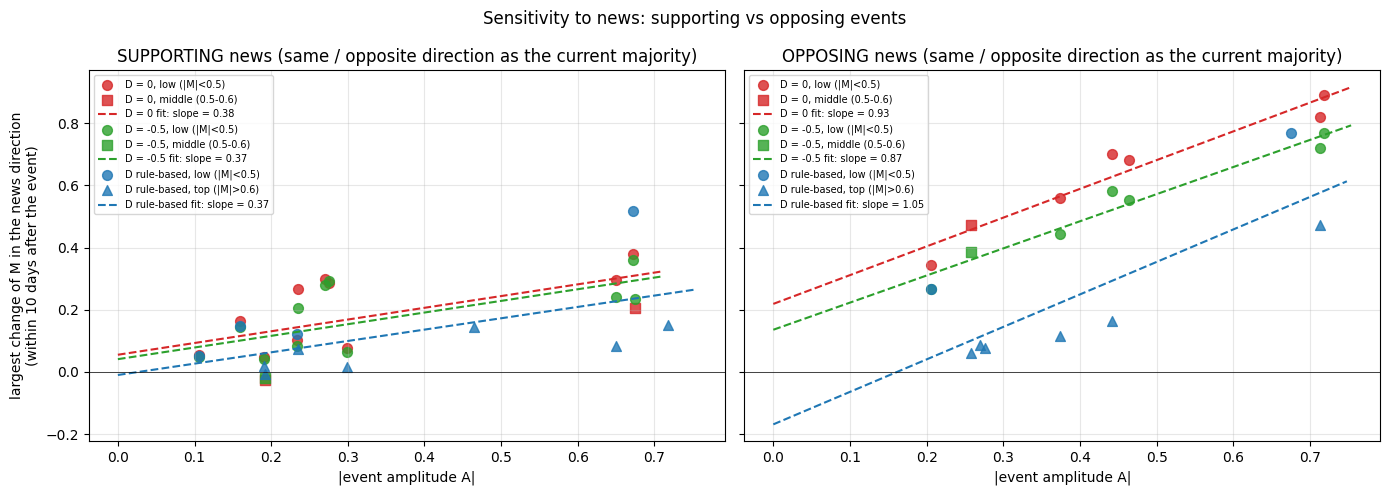

In [77]:
# ============================================================
# STATISTICS CELL 1b: SENSITIVITY, supporting and opposing news in SEPARATE panels
# x = |event amplitude A|
# y = largest change of M in the direction of the news within `window` days after the event
#     = max over tau of  sign(A) * ( M(t0 + tau) - M(t0) )
# ============================================================
window = 10          # days after the event in which the peak is searched (= event spacing / fade)
band_markers = {'low (|M|<0.5)': 'o', 'middle (0.5-0.6)': 's', 'top (|M|>0.6)': '^'}

# collect one point per (condition, event)
pts = []
for name in names:
    M = np.asarray(R[name]['M'], dtype=float)
    for day, A, fade in events:
        t0 = int(day)
        if t0 < 1 or t0 + window > len(M):
            continue
        s = np.sign(A)
        peak = (s * (M[t0:t0 + window] - M[t0 - 1])).max()     # baseline = day before, window = ages 0..9
        relation = 'supporting' if np.sign(M[t0]) == s else 'opposing'
        pts.append(dict(condition=name, A=abs(A), peak=peak, band=band_of(M[t0]), relation=relation))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
print(f"{'relation':11s} {'condition':15s} {'n':>3s} {'mean peak':>9s} {'slope':>7s} {'R^2':>6s}")
for ax, relation in zip(axes, ['supporting', 'opposing']):
    for name in names:
        sel = [p for p in pts if p['condition'] == name and p['relation'] == relation]
        if not sel:
            continue
        for band, mk in band_markers.items():
            sb = [p for p in sel if p['band'] == band]
            if sb:
                ax.scatter([p['A'] for p in sb], [p['peak'] for p in sb], marker=mk, s=50,
                           color=colors.get(name), alpha=0.8, label=f'{name}, {band}')
        a = np.array([p['A'] for p in sel]); y = np.array([p['peak'] for p in sel])
        if len(sel) > 2:
            slope, icpt = np.polyfit(a, y, 1)
            r2 = np.corrcoef(a, y)[0, 1] ** 2
            xs = np.linspace(0, a.max() * 1.05, 50)
            ax.plot(xs, slope * xs + icpt, '--', color=colors.get(name), lw=1.5,
                    label=f'{name} fit: slope = {slope:.2f}')
        else:
            slope, r2 = np.nan, np.nan
        print(f"{relation:11s} {name:15s} {len(sel):3d} {y.mean():9.3f} {slope:7.2f} {r2:6.2f}")
    ax.axhline(0, color='k', lw=0.5)
    ax.set_title(f'{relation.upper()} news (same / opposite direction as the current majority)')
    ax.set_xlabel('|event amplitude A|'); ax.grid(alpha=0.3); ax.legend(fontsize=7)
axes[0].set_ylabel(f'largest change of M in the news direction\n(within {window} days after the event)')
fig.suptitle('Sensitivity to news: supporting vs opposing events')
plt.tight_layout(); plt.show()

13 events with the rule-based run in the top band: 6 opposing, 7 supporting

relation    condition         n mean start M mean peak   slope    R^2
supporting  D = 0             7        +0.19     0.305    1.11   0.60
supporting  D = -0.5          7        +0.23     0.255    0.97   0.62
supporting  D rule-based      7        +0.81     0.060    0.20   0.64
opposing    D = 0             6        +0.24     0.493    1.09   0.81
opposing    D = -0.5          6        +0.27     0.430    0.96   0.91
opposing    D rule-based      6        +0.82     0.166    0.99   0.95


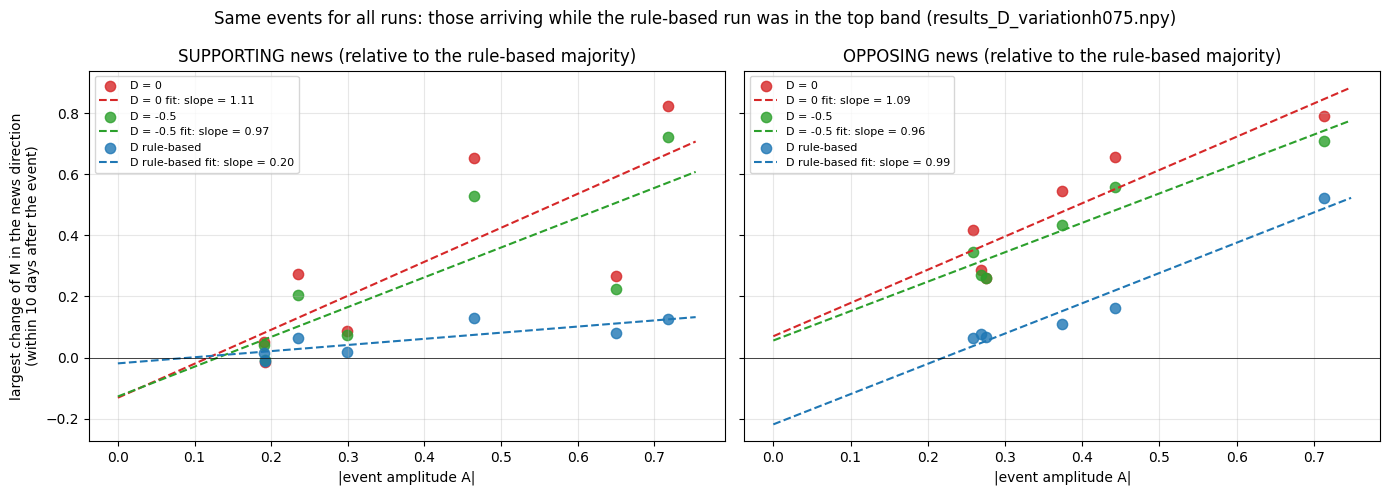

In [78]:
# ============================================================
# STATISTICS CELL 1c: SENSITIVITY on the SAME events, chosen where the RULE-BASED run is in the top band
# x = |event amplitude A|,  y = largest change of M in the direction of the news within `window` days
# supporting / opposing is defined by the RULE-BASED run's majority (same label for all runs)
# ============================================================
window   = 10
ref_name = 'D rule-based'          # the run that defines which events are used
min_absM = 0.6                     # top band: |M| > 0.6 at the event day

M_ref = np.asarray(R[ref_name]['M'], dtype=float)
chosen = []
for day, A, fade in events:
    t0 = int(day)
    if t0 + window < len(M_ref) and abs(M_ref[t0]) > min_absM:
        relation = 'supporting' if np.sign(M_ref[t0]) == np.sign(A) else 'opposing'
        chosen.append((t0, A, relation))
print(f"{len(chosen)} events with the rule-based run in the top band: "
      f"{sum(r == 'opposing' for *_, r in chosen)} opposing, {sum(r == 'supporting' for *_, r in chosen)} supporting")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
print(f"\n{'relation':11s} {'condition':15s} {'n':>3s} {'mean start M':>12s} {'mean peak':>9s} {'slope':>7s} {'R^2':>6s}")
for ax, relation in zip(axes, ['supporting', 'opposing']):
    ev = [(t0, A) for t0, A, r in chosen if r == relation]
    for name in names:
        M = np.asarray(R[name]['M'], dtype=float)
        a, y, m0 = [], [], []
        for t0, A in ev:
            s = np.sign(A)
            y.append((s * (M[t0 + 1:t0 + window + 1] - M[t0])).max())
            a.append(abs(A)); m0.append(M[t0])
        if not a:
            continue
        a, y = np.array(a), np.array(y)
        ax.scatter(a, y, s=55, color=colors.get(name), alpha=0.8, label=name)
        if len(a) > 2:
            slope, icpt = np.polyfit(a, y, 1)
            r2 = np.corrcoef(a, y)[0, 1] ** 2
            xs = np.linspace(0, a.max() * 1.05, 50)
            ax.plot(xs, slope * xs + icpt, '--', color=colors.get(name), lw=1.5,
                    label=f'{name} fit: slope = {slope:.2f}')
        else:
            slope, r2 = np.nan, np.nan
        print(f"{relation:11s} {name:15s} {len(a):3d} {np.mean(m0):+12.2f} {y.mean():9.3f} {slope:7.2f} {r2:6.2f}")
    ax.axhline(0, color='k', lw=0.5)
    ax.set_title(f'{relation.upper()} news (relative to the rule-based majority)')
    ax.set_xlabel('|event amplitude A|'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel(f'largest change of M in the news direction\n(within {window} days after the event)')
fig.suptitle(f'Same events for all runs: those arriving while the rule-based run was in the top band ({results_file})')
plt.tight_layout(); plt.show()

condition         n              amplitude               relation                   band   amplitude x relation
D = 0            19       0.42 [0.24-0.72]       0.70 [0.51-0.85]       0.03 [0.00-0.23]       0.89 [0.83-0.96]
D = -0.5         19       0.48 [0.30-0.76]       0.58 [0.39-0.77]       0.03 [0.00-0.24]       0.85 [0.77-0.95]
D rule-based     19       0.40 [0.16-0.74]       0.11 [0.00-0.39]       0.23 [0.01-0.59]       0.74 [0.43-0.97]


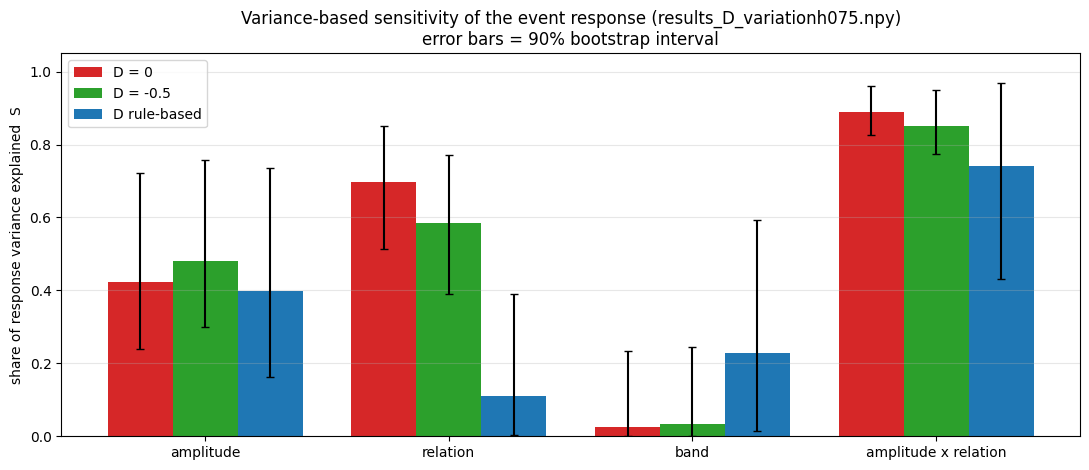

In [79]:
# ============================================================
# STATISTICS CELL 6: VARIANCE-BASED SENSITIVITY of the event response
# S_x = Var( E[y | x] ) / Var(y)      (correlation ratio = first-order Sobol index of x)
#   y = largest change of M in the direction of the news (baseline = day before, window = ages 0..9)
#   x = amplitude (binned), band at the event, supporting/opposing, and amplitude x relation together
# ============================================================
window   = 10        # ages 0..window-1 of the event
n_bins_A = 3         # amplitude groups (keep small: few events per run)
n_boot   = 1000      # bootstrap repetitions for the uncertainty of S

def corr_ratio(y, groups):
    y = np.asarray(y, float); groups = np.asarray(groups)
    if y.var() == 0 or len(np.unique(groups)) < 2:
        return np.nan
    between = sum((groups == g).sum() * (y[groups == g].mean() - y.mean())**2 for g in np.unique(groups))
    return between / (len(y) * y.var())

def event_table(M):
    rows = []
    for day, A, fade in events:
        t0 = int(day)
        if t0 < 1 or t0 + window > len(M):
            continue
        s = np.sign(A)
        y = (s * (M[t0:t0 + window] - M[t0 - 1])).max()
        rows.append(dict(A=abs(A), y=y, band=band_of(M[t0 - 1]),
                         relation='supporting' if np.sign(M[t0 - 1]) == s else 'opposing'))
    return rows

# amplitude bins: equal-count groups over all events (the same cuts for every condition)
A_all = np.abs(events[:, 1])
cuts  = np.quantile(A_all, np.linspace(0, 1, n_bins_A + 1)[1:-1])
A_bin = lambda a: int(np.searchsorted(cuts, a))

inputs = ['amplitude', 'relation', 'band', 'amplitude x relation']
results_S = {}
rng = np.random.default_rng(0)
print(f"{'condition':15s} {'n':>3s} " + " ".join(f"{k:>22s}" for k in inputs))
for name in names:
    rows = event_table(np.asarray(R[name]['M'], dtype=float))
    y   = np.array([r['y'] for r in rows])
    grp = {'amplitude':            np.array([A_bin(r['A']) for r in rows]),
           'relation':             np.array([r['relation'] for r in rows]),
           'band':                 np.array([r['band'] for r in rows]),
           'amplitude x relation': np.array([f"{A_bin(r['A'])}-{r['relation']}" for r in rows])}
    out = {}
    for k in inputs:
        S = corr_ratio(y, grp[k])
        boots = []
        for _ in range(n_boot):                         # resample events to see how stable S is
            idx = rng.integers(0, len(y), len(y))
            boots.append(corr_ratio(y[idx], grp[k][idx]))
        lo, hi = np.nanpercentile(boots, [5, 95]) if np.isfinite(boots).any() else (np.nan, np.nan)
        out[k] = (S, lo, hi)
    results_S[name] = out
    print(f"{name:15s} {len(y):3d} " + " ".join(
        f"{out[k][0]:6.2f} [{out[k][1]:4.2f}-{out[k][2]:4.2f}]".rjust(22) for k in inputs))

# ---- plot ----
x = np.arange(len(inputs)); w = 0.8 / len(names)
plt.figure(figsize=(11, 4.8))
for i, name in enumerate(names):
    S  = np.array([results_S[name][k][0] for k in inputs])
    lo = np.array([results_S[name][k][1] for k in inputs])
    hi = np.array([results_S[name][k][2] for k in inputs])
    plt.bar(x + i * w, S, w, color=colors.get(name), label=name,
            yerr=[np.nan_to_num(S - lo), np.nan_to_num(hi - S)], capsize=3)
plt.xticks(x + w * (len(names) - 1) / 2, inputs)
plt.ylabel('share of response variance explained  S')
plt.ylim(0, 1.05); plt.grid(alpha=0.3, axis='y'); plt.legend()
plt.title(f'Variance-based sensitivity of the event response ({results_file})\n'
          'error bars = 90% bootstrap interval')
plt.tight_layout(); plt.show()


D = 0  (n = 19 events, all three together explain 0.86)
   amplitude   S =  0.35 [ 0.14, 0.69]  S_T =  0.16 [ 0.03, 0.37]  S_T-S = -0.20 [-0.58, 0.12]  Shapley =  0.25 [ 0.14, 0.44]
   relation    S =  0.68 [ 0.50, 0.83]  S_T =  0.57 [ 0.22, 0.75]  S_T-S = -0.11 [-0.54, 0.14]  Shapley =  0.62 [ 0.43, 0.72]
   band        S =  0.00 [ 0.00, 0.21]  S_T =  0.02 [ 0.00, 0.08]  S_T-S =  0.02 [-0.17, 0.06]  Shapley =  0.00 [-0.00, 0.11]

D = -0.5  (n = 19 events, all three together explain 0.78)
   amplitude   S =  0.42 [ 0.21, 0.70]  S_T =  0.22 [ 0.06, 0.46]  S_T-S = -0.20 [-0.52, 0.11]  Shapley =  0.31 [ 0.20, 0.50]
   relation    S =  0.56 [ 0.35, 0.76]  S_T =  0.42 [ 0.14, 0.62]  S_T-S = -0.14 [-0.48, 0.13]  Shapley =  0.48 [ 0.32, 0.63]
   band        S =  0.00 [ 0.00, 0.20]  S_T = -0.01 [-0.02, 0.06]  S_T-S = -0.01 [-0.18, 0.04]  Shapley = -0.01 [-0.01, 0.10]

D rule-based  (n = 19 events, all three together explain 0.96)
   amplitude   S =  0.32 [ 0.06, 0.70]  S_T =  0.63 [ 0.13, 0.8

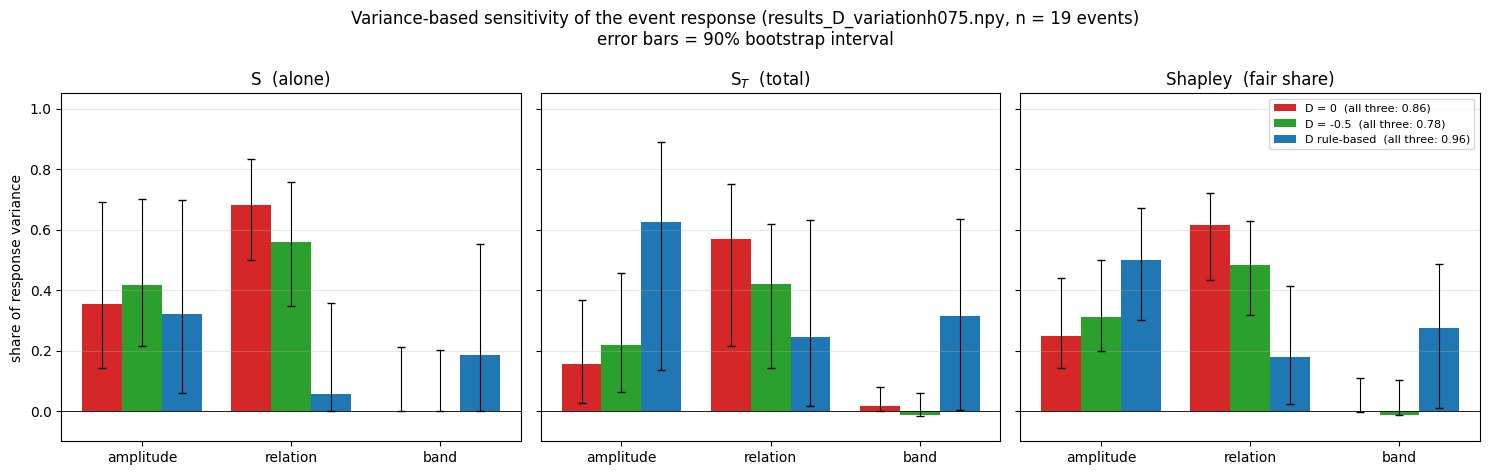

In [80]:
# ============================================================
# STATISTICS CELL 6b: paper-style S, S_T, S_T - S (+ fair share) of the event response
#   Same events and same y as Cell 6 -> no new simulations. Needs Cell 0 and Cell 6.
#   S(x)      = share of Var(y) explained by x ALONE                     (red)
#   S_T(x)    = S(all) - S(all inputs except x)                          (blue)
#               = what is lost if x is dropped (x alone + x together with others)
#   S_T - S   = > 0 : x works together with other inputs (interaction)   (yellow)
#               < 0 : x carries the same information as another input (overlap)
#   Shapley   = fair share of S(all) for x; the three Shapley bars add up
#               exactly to S(all) -> use this to say which input dominates (grey)
#   S(all)    = explained by amplitude, relation and band together (dashed line);
#               1 - S(all) = spin noise that no input explains
# All S are bias-corrected (epsilon^2) because groups of 1-2 events always "explain" too much.
# ============================================================
from itertools import combinations
from math import factorial

inputs_b      = ['amplitude', 'relation', 'band']
n_boot        = 1000
show_whiskers = True      # False = clean bars like the paper (intervals are still printed)

def corr_ratio_adj(y, groups):
    """bias-corrected correlation ratio (epsilon^2): penalises having many small groups"""
    y = np.asarray(y, float); groups = np.asarray(groups)
    n, labels = len(y), np.unique(groups)
    k = len(labels)
    if y.var() == 0 or k < 2 or n - k < 1:
        return 0.0 if k < 2 else np.nan
    ss_tot = ((y - y.mean())**2).sum()
    ss_bet = sum((groups == g).sum() * (y[groups == g].mean() - y.mean())**2 for g in labels)
    ms_within = (ss_tot - ss_bet) / (n - k)
    return max(0.0, (ss_bet - (k - 1) * ms_within) / ss_tot)

def combine(cols):
    """one group label per event from several inputs, e.g. '2|opposing|top'"""
    if len(cols) == 0:
        return np.zeros(0)
    return np.array(['|'.join(map(str, t)) for t in zip(*cols)])

def indices(y, G):
    p = len(inputs_b)
    v = {(): 0.0}                                            # S of every subset of inputs
    for r in range(1, p + 1):
        for sub in combinations(inputs_b, r):
            v[sub] = corr_ratio_adj(y, combine([G[o] for o in sub]))
    S_all = v[tuple(inputs_b)]
    out = {'all': S_all}
    for x in inputs_b:
        rest = tuple(o for o in inputs_b if o != x)
        S, ST = v[(x,)], S_all - v[rest]
        sh = 0.0                                             # Shapley: average gain of adding x
        for r in range(p):
            for sub in combinations(rest, r):
                with_x = tuple(o for o in inputs_b if o in sub or o == x)
                sh += factorial(r) * factorial(p - r - 1) / factorial(p) * (v[with_x] - v[sub])
        out[x] = (S, ST, ST - S, sh)
    return out

results_b = {}
rng = np.random.default_rng(0)
for name in names:
    rows = event_table(np.asarray(R[name]['M'], dtype=float))
    y = np.array([r['y'] for r in rows])
    G = {'amplitude': np.array([A_bin(r['A']) for r in rows]),
         'relation':  np.array([r['relation'] for r in rows]),
         'band':      np.array([r['band'] for r in rows])}
    est = indices(y, G)
    boots = []
    for _ in range(n_boot):                                  # resample events
        idx = rng.integers(0, len(y), len(y))
        boots.append(indices(y[idx], {k: v[idx] for k, v in G.items()}))
    ci = {x: np.nanpercentile([b[x] for b in boots], [5, 95], axis=0) for x in inputs_b}
    results_b[name] = (est, ci, len(y))
    print(f"\n{name}  (n = {len(y)} events, all three together explain {est['all']:.2f})")
    for x in inputs_b:
        print(f"   {x:10s}" + "".join(
            f"  {lab} = {est[x][j]:5.2f} [{ci[x][0][j]:5.2f},{ci[x][1][j]:5.2f}]"
            for j, lab in enumerate(['S', 'S_T', 'S_T-S', 'Shapley'])))

# balance check: are the inputs mixed, or do they come together (overlap)?
rows = event_table(np.asarray(R[names[-1]]['M'], dtype=float))
print(f"\nevents per amplitude group x relation ({names[-1]}):")
for b in range(n_bins_A):
    print(f"   amplitude group {b}: " + ", ".join(
        f"{rel} {sum(1 for r in rows if A_bin(r['A']) == b and r['relation'] == rel)}"
        for rel in ['supporting', 'opposing']))

# ---- plot: same reading as Cell 6 (one colour per condition), one panel per measure ----
measures = [(0, 'S  (alone)'), (1, 'S$_T$  (total)'), (3, 'Shapley  (fair share)')]
fig, axes = plt.subplots(1, len(measures), figsize=(15, 4.8), sharey=True)
x = np.arange(len(inputs_b)); w = 0.8 / len(names)
for ax, (j, title) in zip(axes, measures):
    for i, name in enumerate(names):
        est, ci, n = results_b[name]
        v  = np.array([est[k][j] for k in inputs_b])
        lo = np.array([ci[k][0][j] for k in inputs_b])
        hi = np.array([ci[k][1][j] for k in inputs_b])
        err = [np.clip(np.nan_to_num(v - lo), 0, None), np.clip(np.nan_to_num(hi - v), 0, None)]
        ax.bar(x + i * w, v, w, color=colors.get(name), label=f"{name}  (all three: {est['all']:.2f})",
               yerr=err if show_whiskers else None, capsize=3, error_kw=dict(lw=0.8))
    ax.axhline(0, color='k', lw=0.6)
    ax.set_xticks(x + w * (len(names) - 1) / 2); ax.set_xticklabels(inputs_b)
    ax.set_title(title); ax.grid(alpha=0.3, axis='y')
axes[0].set_ylabel('share of response variance'); axes[0].set_ylim(-0.1, 1.05)
axes[-1].legend(fontsize=8, loc='upper right')
fig.suptitle(f'Variance-based sensitivity of the event response ({results_file}, n = {results_b[names[0]][2]} events)'
             + ('\nerror bars = 90% bootstrap interval' if show_whiskers else ''))
plt.tight_layout(); plt.show()

condition       best lag  max corr    (top band) best lag  max corr
D = 0                  0      0.65                      -       nan
D = -0.5               0      0.69                      -       nan
D rule-based           0      0.65                      0      0.68


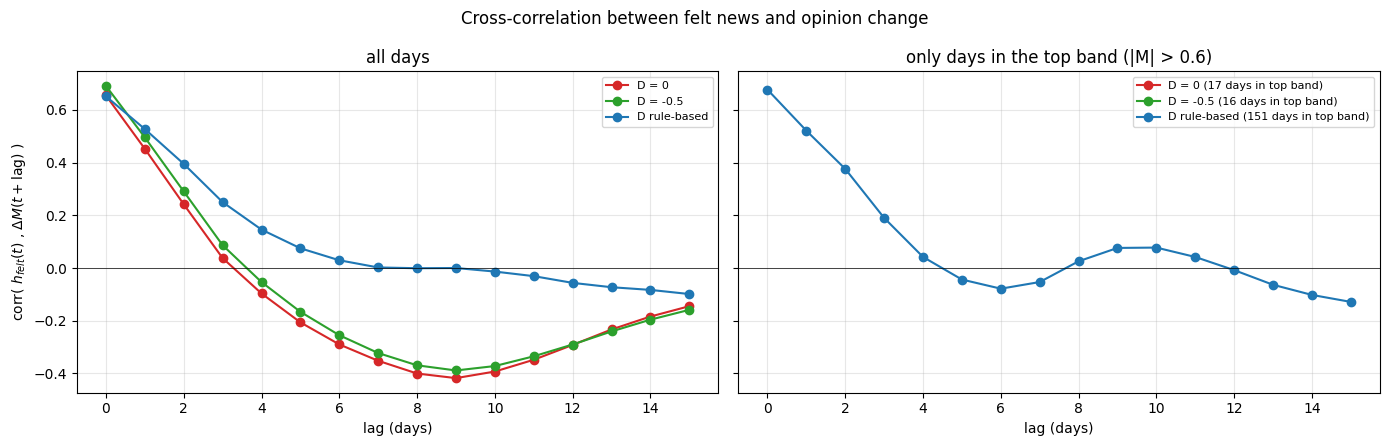

In [86]:
# ============================================================
# STATISTICS CELL 2: CROSS-CORRELATION between felt news and the change of opinion
# corr( h_felt(t) , dM(t + lag) ),  dM(t) = M(t+1) - M(t)
# ============================================================
max_lag = 15

def xcorr(x, y, max_lag, mask=None):
    out = []
    for lag in range(max_lag + 1):
        a, b = x[:len(x) - lag], y[lag:]
        if mask is not None:
            m = mask[:len(x) - lag]
            a, b = a[m], b[m]
        out.append(np.corrcoef(a, b)[0, 1] if len(a) > 5 and a.std() > 0 and b.std() > 0 else np.nan)
    return np.array(out)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
lags = np.arange(max_lag + 1)
print(f"{'condition':15s} {'best lag':>8s} {'max corr':>9s}   {'(top band) best lag':>20s} {'max corr':>9s}")
for name in names:
    M = np.asarray(R[name]['M'], dtype=float)
    h = np.asarray(R[name]['h_felt'], dtype=float)
    dM = np.diff(M)                      # dM[t] = M[t+1] - M[t]
    hh = h[:len(dM)]
    c_all = xcorr(hh, dM, max_lag)
    top = np.abs(M[:len(dM)]) > 0.6      # only times when the society sat in the top band
    c_top = xcorr(hh, dM, max_lag, mask=top) if top.sum() > 20 else np.full(max_lag + 1, np.nan)
    axA.plot(lags, c_all, 'o-', color=colors.get(name), label=name)
    axB.plot(lags, c_top, 'o-', color=colors.get(name), label=f'{name} ({top.sum()} days in top band)')
    k = np.nanargmax(c_all)
    kt = np.nanargmax(c_top) if np.isfinite(c_top).any() else None
    print(f"{name:15s} {k:8d} {c_all[k]:9.2f}   {('-' if kt is None else kt):>20} "
          f"{(np.nan if kt is None else c_top[kt]):9.2f}")
for ax, t in [(axA, 'all days'), (axB, 'only days in the top band (|M| > 0.6)')]:
    ax.axhline(0, color='k', lw=0.5); ax.set_xlabel('lag (days)'); ax.set_title(t)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
axA.set_ylabel(r'corr( $h_{felt}(t)$ , $\Delta M(t+\mathrm{lag})$ )')
plt.suptitle('Cross-correlation between felt news and opinion change')
plt.tight_layout(); plt.show()

In [82]:
# check: is the dip still there when the next event is excluded?
days = events[:, 0].astype(int)
for name in names:
    M = np.asarray(R[name]['M'], float); h = np.asarray(R[name]['h_felt'], float)
    dM = np.diff(M); hh = h[:len(dM)]
    clean = []
    for lag in range(10):                          # up to 9: beyond that every pair crosses into the next event
        t = np.arange(len(dM) - lag)
        last = np.array([days[days <= tt].max() if (days <= tt).any() else -99 for tt in t])
        same = (t + lag) < last + 10               # t+lag still before the next event begins
        clean.append(np.corrcoef(hh[t][same], dM[t + lag][same])[0, 1])
    print(f"{name:15s} same-event only:", np.round(clean, 2))

D = 0           same-event only: [ 0.67  0.49  0.32  0.18 -0.   -0.21 -0.38 -0.46 -0.55 -0.57]
D = -0.5        same-event only: [ 0.71  0.54  0.38  0.25  0.09 -0.1  -0.28 -0.37 -0.5  -0.54]
D rule-based    same-event only: [ 0.68  0.58  0.48  0.42  0.32  0.22  0.15  0.11  0.08 -0.03]


condition        tau_int (days)  ACF reaches 1/e at
D = 0                      36.6                  21
D = -0.5                   26.3                  16
D rule-based               26.3                  16


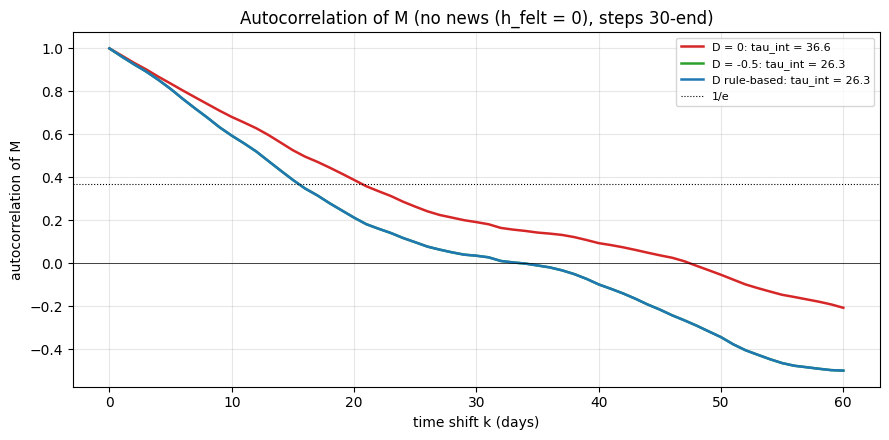

In [87]:
# ============================================================
# STATISTICS CELL 3: AUTOCORRELATION of M (intrinsic memory) - best with the NO-news runs
# ============================================================
max_k  = 60          # largest time shift (days)
skip   = 30          # drop the start, where M is still relaxing from its initial value
source = R0 if R0 is not None else R
label  = 'no news (h_felt = 0)' if R0 is not None else 'with news'

def acf(x, max_k):
    x = x - x.mean()
    v = np.dot(x, x) / len(x)
    return np.array([1.0] + [np.dot(x[:-k], x[k:]) / len(x) / v for k in range(1, max_k + 1)])

plt.figure(figsize=(9, 4.5))
print(f"{'condition':15s} {'tau_int (days)':>15s} {'ACF reaches 1/e at':>19s}")
for name in source:
    M = np.asarray(source[name]['M'], dtype=float)[skip:]
    c = acf(M, max_k)
    # integrated autocorrelation time: 1 + 2 * sum of the ACF until it first drops below 0
    cut = np.argmax(c < 0) if (c < 0).any() else len(c)
    tau_int = 1 + 2 * c[1:cut].sum()
    e_fold = np.argmax(c < np.exp(-1)) if (c < np.exp(-1)).any() else np.nan
    plt.plot(range(max_k + 1), c, color=colors.get(name), lw=1.8, label=f'{name}: tau_int = {tau_int:.1f}')
    print(f"{name:15s} {tau_int:15.1f} {e_fold:>19}")
plt.axhline(np.exp(-1), color='k', ls=':', lw=0.8, label='1/e')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel('time shift k (days)'); plt.ylabel('autocorrelation of M')
plt.title(f'Autocorrelation of M ({label}, steps {skip}-end)')
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

--- no news, from the start ---
  D = 0           start = +0.359, half-life = 51 days, tau = 426.9 days
  D = -0.5        start = +0.359, half-life = 52 days, tau = 843.2 days
  D rule-based    start = +0.359, half-life = 52 days, tau = 843.2 days
--- with news, after day 255 (quiet) ---
  D = 0           start = -0.012, half-life = 13 days, tau = 24.9 days
  D = -0.5        start = -0.101, half-life = nan days, tau = 443.1 days
  D rule-based    start = -0.100, half-life = nan days, tau = 445.0 days


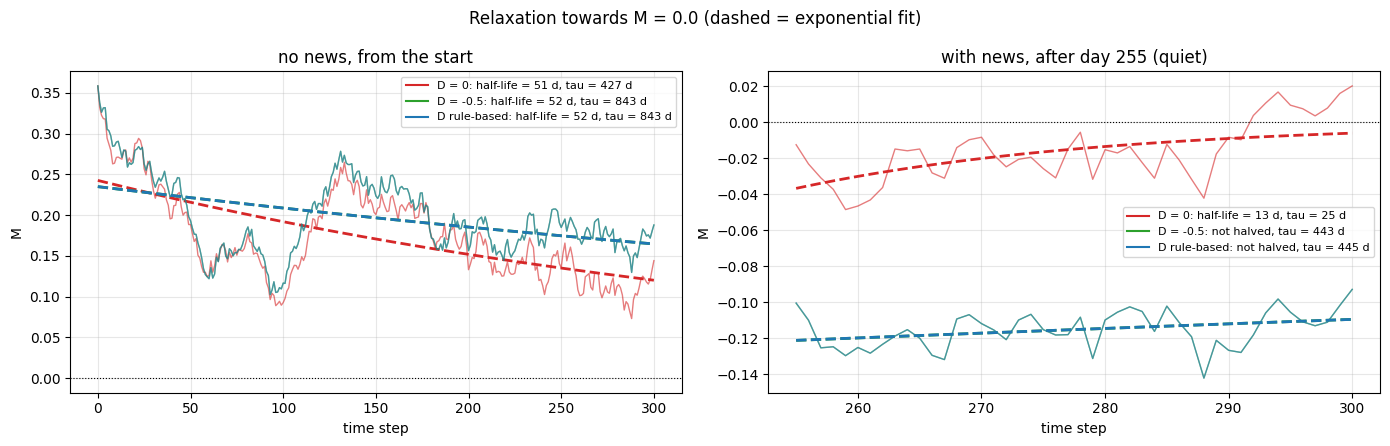

In [88]:
# ============================================================
# STATISTICS CELL 5: RELAXATION TIME after a perturbation
#  (a) no-news runs: relaxation from the initial state (M0 = 0.36) towards the resting state
#  (b) news runs: the quiet stretch after the last event has faded
# Two measures:
#  - half-life: days until the distance to the resting state has halved (no fitting needed)
#  - tau: exponential fit  M(t) - M_rest = a * exp(-(t - t_start)/tau)
# ============================================================
from scipy.optimize import curve_fit

M_rest   = 0.0       # resting state the system relaxes to (0 when no lock-in; e.g. 0.78 if it stays locked)
smooth_w = 5         # moving-average window used before measuring the half-life (removes noise)

def half_life(t, y, rest, w):
    ys = np.convolve(y, np.ones(w) / w, mode='valid'); ts = t[:len(ys)]
    d = np.abs(ys - rest)
    below = np.where(d <= 0.5 * d[0])[0]
    return (ts[below[0]] - ts[0]) if len(below) else np.nan

def fit_tau(t, y, rest):
    f = lambda t, a, tau: a * np.exp(-(t - t[0]) / tau) + rest
    try:
        p, _ = curve_fit(f, t, y, p0=[y[0] - rest, 20.0], bounds=([-2, 0.5], [2, 5000]), maxfev=20000)
        return p, f
    except Exception:
        return None, f

last_fade = int((events[:, 0] + events[:, 2]).max())     # day on which the last event is fully gone
windows = []
if R0 is not None:
    windows.append(('no news, from the start', R0, 0, None))
windows.append((f'with news, after day {last_fade} (quiet)', R, last_fade, None))

fig, axes = plt.subplots(1, len(windows), figsize=(7 * len(windows), 4.5))
axes = np.atleast_1d(axes)
for ax, (title, source, a, b) in zip(axes, windows):
    print(f"--- {title} ---")
    for name in source:
        M = np.asarray(source[name]['M'], dtype=float)
        bb = len(M) if b is None else min(b, len(M))
        t = np.arange(a, bb); y = M[a:bb]
        hl = half_life(t, y, M_rest, smooth_w)
        p, f = fit_tau(t, y, M_rest)
        ax.plot(t, y, color=colors.get(name), lw=1, alpha=0.6)
        lab = f'{name}: half-life = {hl:.0f} d' if np.isfinite(hl) else f'{name}: not halved'
        if p is not None:
            ax.plot(t, f(t, *p), '--', color=colors.get(name), lw=2)
            lab += f', tau = {p[1]:.0f} d'
        ax.plot([], [], color=colors.get(name), label=lab)
        print(f"  {name:15s} start = {y[0]:+.3f}, half-life = {hl} days, "
              f"tau = {('fit failed' if p is None else f'{p[1]:.1f} days')}")
    ax.axhline(M_rest, color='k', ls=':', lw=0.8)
    ax.set_title(title); ax.set_xlabel('time step'); ax.set_ylabel('M')
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle(f'Relaxation towards M = {M_rest} (dashed = exponential fit)')
plt.tight_layout(); plt.show()